# DECRF — Dual Explainability Credit Risk Framework

This notebook implements the full DECRF pipeline across two datasets:
- **German Credit** (UCI, 1994) — academic benchmark
- **Home Credit Default Risk** (Kaggle, 2018) — real-world validation

Each dataset goes through five stages: Preprocessing → Model Training → Evaluation → SHAP → DiCE → Fairness Audit.

# German Dataset

## 1. Imports & Setup <a id='1'></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import os
from sklearn.model_selection import train_test_split
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import StandardScaler
import optuna
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    f1_score, brier_score_loss,
    roc_curve, precision_recall_curve,
    confusion_matrix, classification_report, 
    accuracy_score, precision_score, recall_score
)
from scipy import stats
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

from fairlearn.metrics import (
    demographic_parity_difference,
    equalized_odds_difference,
    demographic_parity_ratio,
    MetricFrame
)
import time

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

warnings.filterwarnings('ignore')
os.makedirs('outputs', exist_ok=True)
optuna.logging.set_verbosity(optuna.logging.WARNING)

## 2. Load & Explore Data <a id='2'></a>

In [2]:
g_df = pd.read_csv('german_credit_risk.csv')
print(f"Shape: {g_df.shape}")
print(f"Columns: {g_df.columns.tolist()}")
g_df.head()

Shape: (1000, 11)
Columns: ['Unnamed: 0', 'Age', 'Sex', 'Job', 'Housing', 'Saving accounts', 'Checking account', 'Credit amount', 'Duration', 'Purpose', 'Risk']


,Unnamed: 0,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Risk
0,0,67,male,2,own,NaN,little,1169,6,radio/TV,good
1,1,22,female,2,own,little,moderate,5951,48,radio/TV,bad
2,2,49,male,1,own,little,NaN,2096,12,education,good
3,3,45,male,2,free,little,little,7882,42,furniture/equipment,good
4,4,53,male,2,free,little,little,4870,24,car,bad


In [3]:
print("Data Types:")
print(g_df.dtypes)
print(f"\nMissing values:\n{g_df.isnull().sum()}")
print(f"\nDuplicate rows: {g_df.duplicated().sum()}")

Data Types:
Unnamed: 0           int64
Age                  int64
Sex                 object
Job                  int64
Housing             object
Saving accounts     object
Checking account    object
Credit amount        int64
Duration             int64
Purpose             object
Risk                object
dtype: object

Missing values:
Unnamed: 0            0
Age                   0
Sex                   0
Job                   0
Housing               0
Saving accounts     183
Checking account    394
Credit amount         0
Duration              0
Purpose               0
Risk                  0
dtype: int64

Duplicate rows: 0


In [4]:
print("\nMissing value audit:")
for col in g_df.columns:
    n_missing = g_df[col].isnull().sum()
    if n_missing > 0:
        print(f"  {col}: {n_missing} missing ({n_missing/len(g_df):.1%})")


Missing value audit:
  Saving accounts: 183 missing (18.3%)
  Checking account: 394 missing (39.4%)


We have 06 categorical feastures and 5 numerical. Additionally, we can notice that the is some missing values. The missing values in 'saving account' and 'checking account' need to be handled using an appropriate imputation technique.

In [5]:
g_df.drop(columns=['Unnamed: 0'], inplace=True)

In [6]:
g_df['Risk'] = g_df['Risk'].map({'good': 0, 'bad': 1})
print(f"\nTarget distribution:")
print(f"  Non-default (0): {(g_df['Risk']==0).sum()} ({(g_df['Risk']==0).mean():.1%})")
print(f"  Default     (1): {(g_df['Risk']==1).sum()} ({(g_df['Risk']==1).mean():.1%})")


Target distribution:
  Non-default (0): 700 (70.0%)
  Default     (1): 300 (30.0%)


In [7]:
# Define feature types
categorical_features = g_df.select_dtypes(include=['object']).columns.tolist()
categorical_features = [c for c in categorical_features if c in g_df.columns]
print("Categorical features :", categorical_features)
numerical_features = [c for c in g_df.columns
                      if c != 'Risk'
                      and c not in categorical_features]
print("Numerical features :", numerical_features)

Categorical features : ['Sex', 'Housing', 'Saving accounts', 'Checking account', 'Purpose']
Numerical features : ['Age', 'Job', 'Credit amount', 'Duration']


In [8]:
# Categorical feature distributions
for col in categorical_features:
    print(g_df[col].value_counts(), "\n")

Sex
male      690
female    310
Name: count, dtype: int64 

Housing
own     713
rent    179
free    108
Name: count, dtype: int64 

Saving accounts
little        603
moderate      103
quite rich     63
rich           48
Name: count, dtype: int64 

Checking account
little      274
moderate    269
rich         63
Name: count, dtype: int64 

Purpose
car                    337
radio/TV               280
furniture/equipment    181
business                97
education               59
repairs                 22
domestic appliances     12
vacation/others         12
Name: count, dtype: int64 



In [9]:
# Numerical feature distributions
for col in numerical_features[:-1]: # exclude target column
    print(f"{col}:\n", g_df[col].value_counts(bins=10), "\n")

Age:
 (24.6, 30.2]                  262
(30.2, 35.8]                  177
(35.8, 41.4]                  155
(18.942999999999998, 24.6]    149
(41.4, 47.0]                  106
(47.0, 52.6]                   55
(52.6, 58.2]                   42
(58.2, 63.8]                   26
(63.8, 69.4]                   21
(69.4, 75.0]                    7
Name: count, dtype: int64 

Job:
 (1.8, 2.1]       630
(0.9, 1.2]       200
(2.7, 3.0]       148
(-0.004, 0.3]     22
(0.3, 0.6]         0
(0.6, 0.9]         0
(1.2, 1.5]         0
(1.5, 1.8]         0
(2.1, 2.4]         0
(2.4, 2.7]         0
Name: count, dtype: int64 

Credit amount:
 (231.825, 2067.4]     445
(2067.4, 3884.8]      293
(3884.8, 5702.2]       97
(5702.2, 7519.6]       80
(7519.6, 9337.0]       38
(9337.0, 11154.4]      19
(11154.4, 12971.8]     14
(12971.8, 14789.2]      8
(14789.2, 16606.6]      5
(16606.6, 18424.0]      1
Name: count, dtype: int64 



## 3. Data Quality Assessment <a id='3'></a>

In [10]:
print(g_df['Saving accounts'].head(10))
print(g_df['Saving accounts'].isna().sum())

0           NaN
1        little
2        little
3        little
4        little
5           NaN
6    quite rich
7        little
8          rich
9        little
Name: Saving accounts, dtype: object
183


In [11]:
# Impute missing values
g_df['Saving accounts']  = g_df['Saving accounts'].fillna('unknown')
g_df['Checking account'] = g_df['Checking account'].fillna('unknown')
print("\nAfter imputation:")
print(f"  Missing values remaining: {g_df.isnull().sum().sum()}")


After imputation:
  Missing values remaining: 0


Saving accounts (183 missing) and Checking account (394 missing). These are both categorical therefore, impute with 'unknown'. This preserves the information that the value was missing, which itself can be predictive (no account = different risk profile).

Data leakage audit:
- All features represent information available at application time.
- No post-decision or outcome-derived features detected.
- Leakage audit: PASSED

## 4. Statistical Analysis & Visualisations <a id='4'></a>

In [12]:
print("Descriptive Statistics:")
g_df[['Age', 'Credit amount', 'Duration']].describe().round(2)

Descriptive Statistics:


,Age,Credit amount,Duration
count,1000.00,1000.00,1000.00
mean,35.55,3271.26,20.90
std,11.38,2822.74,12.06
min,19.00,250.00,4.00
25%,27.00,1365.50,12.00
50%,33.00,2319.50,18.00
75%,42.00,3972.25,24.00
max,75.00,18424.00,72.00


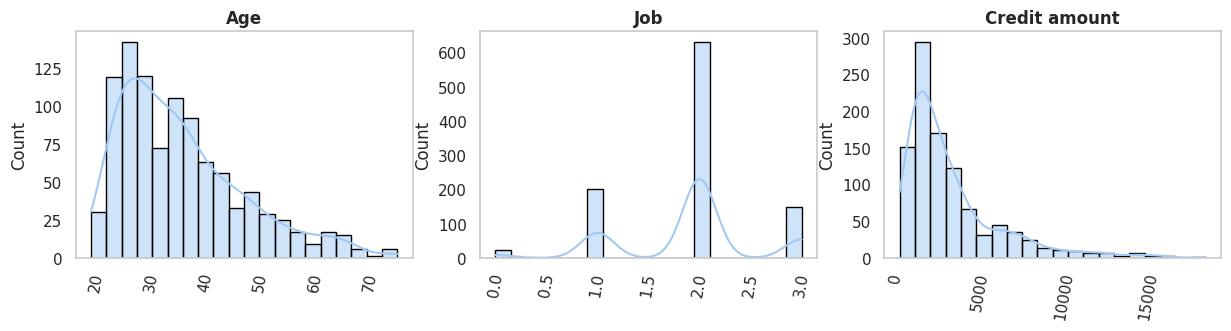

In [13]:
# Visualize distributions of numerical features
sns.set_theme(style="whitegrid", palette="pastel")
plt.figure(figsize=(20, 10))

for i, col in enumerate(numerical_features[:-1]):  # exclude target column
    ax = plt.subplot(3, 4, i + 1)
    plt.grid(visible=False)

    sns.histplot(data=g_df, x=col, ax=ax, kde=True, bins=20, edgecolor='black')

    # Formatting
    ax.set_title(col, fontsize=12, fontweight='bold')
    ax.set_xlabel("")
    ax.set_ylabel("Count")
    ax.tick_params(axis='x', rotation=80)

plt.show()

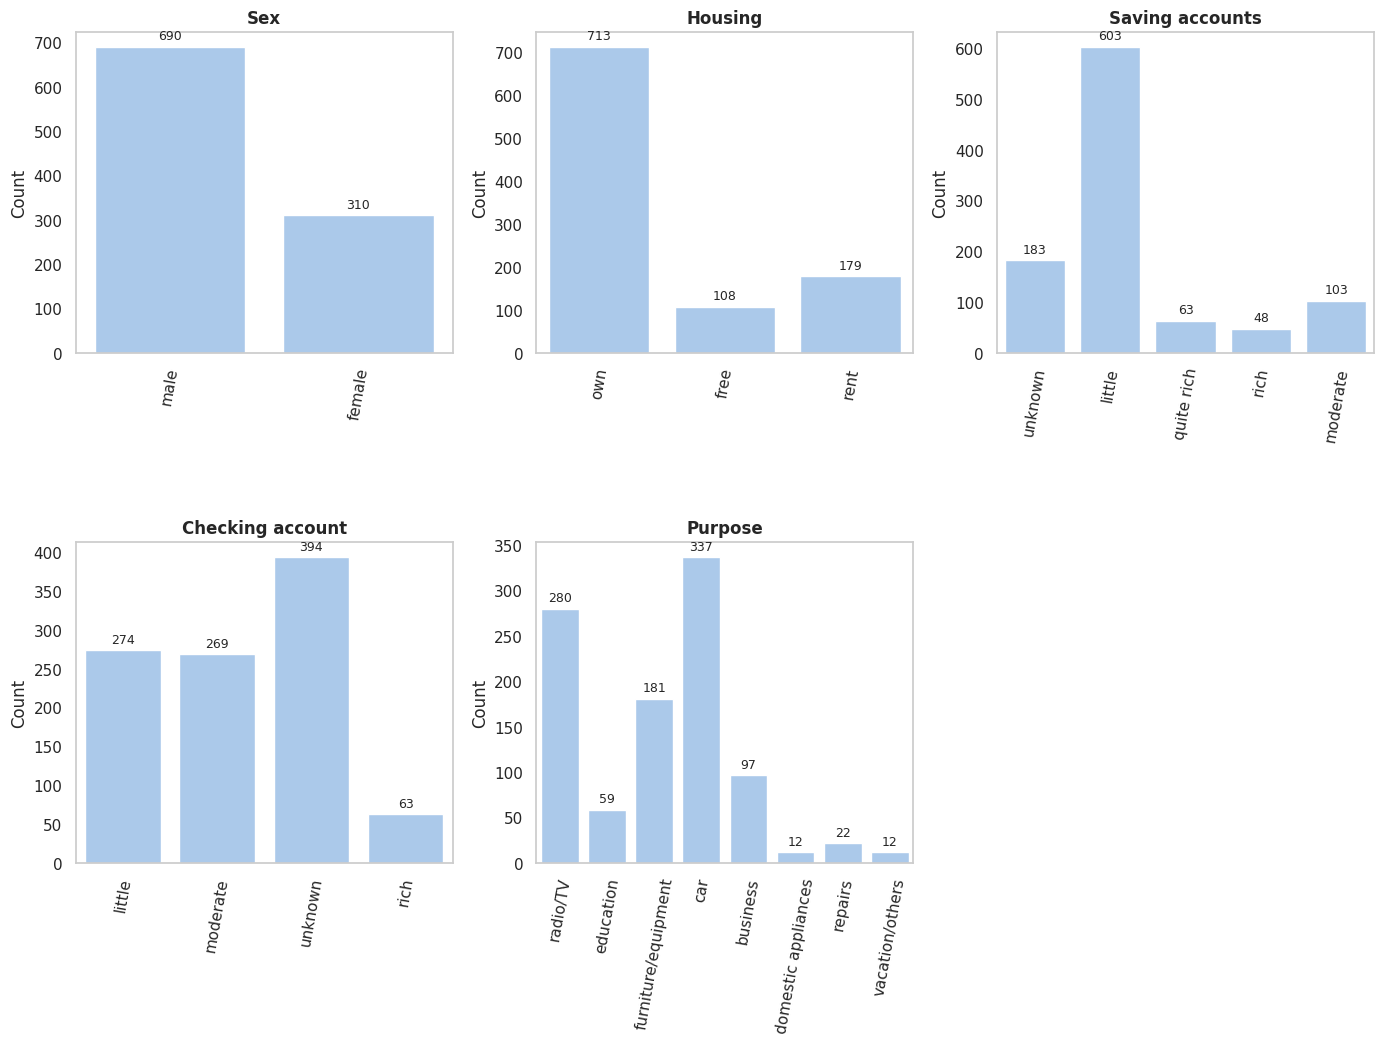

In [14]:
# Visualize of categorical features
plt.figure(figsize=(14, 14))

for i, col in enumerate(categorical_features):
    ax = plt.subplot(3, 3, i + 1)
    plt.grid(visible=False)

    sns.countplot(data=g_df, x=col, ax=ax)

    # Add count labels
    for container in ax.containers:
        ax.bar_label(container, fmt='%d', padding=3, fontsize=9)

    # Formatting
    ax.set_title(col, fontsize=12, fontweight='bold')
    ax.set_xlabel("")
    ax.set_ylabel("Count")
    ax.tick_params(axis='x', rotation=80)

plt.tight_layout()
plt.show()

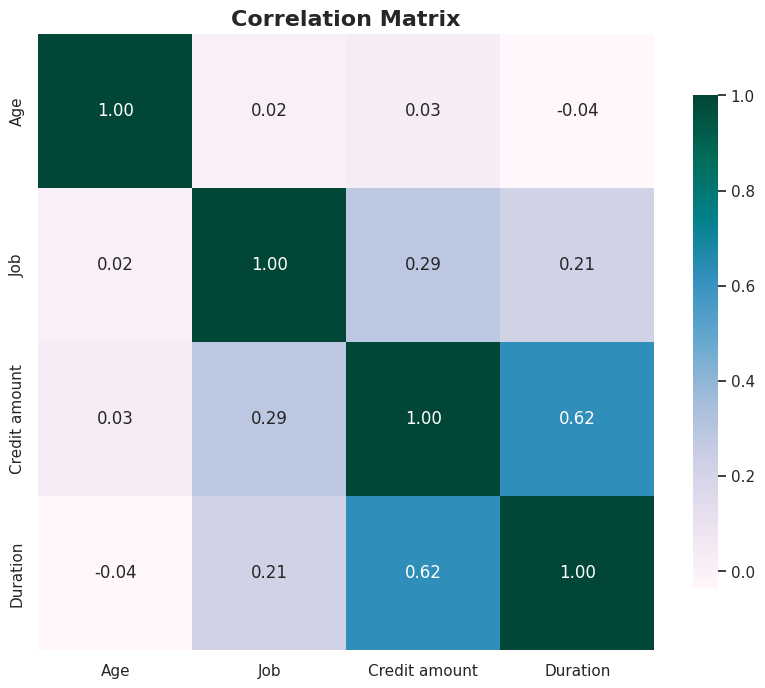

In [15]:
# Correlation matrix
plt.figure(figsize=(10, 8))
corr_matrix = g_df[numerical_features].corr()
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='PuBuGn', square=True, cbar_kws={"shrink": .8})
plt.title("Correlation Matrix", fontsize=16, fontweight='bold')
plt.show()

There is only a small cprrelation between the Credit anount and the duration, which can be explained by the bigger is your credit the longoer its going to take you to pay it.

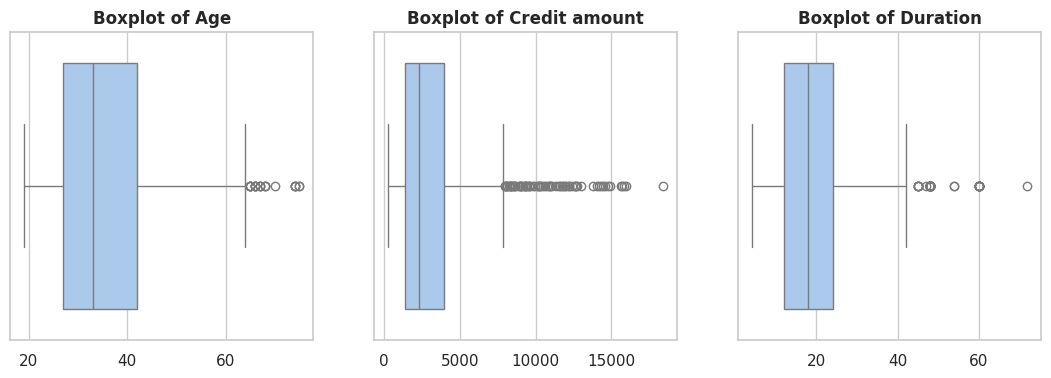

In [16]:
# Outliers detection using boxplots
selected_cols = [numerical_features[i] for i in [0, 2, 3]]
plt.figure(figsize=(18, 4))
for i, col in enumerate(selected_cols):
    ax = plt.subplot(1, 4, i + 1)
    sns.boxplot(x=g_df[col], ax=ax)
    ax.set_title(f"Boxplot of {col}", fontsize=12, fontweight='bold')
    ax.set_xlabel("")


In our case outliers are important to keep since in credit assessment there are different cases and it also can be infulenced by a lot of external factors which makes every credit different.

## 5. Preprocessing & Feature Encoding <a id='5'></a>

German Credit has 1,000 rows — WoE encoding needs larger samples to be stable. One-hot encoding is appropriate here

In [17]:
g_df_encoded = pd.get_dummies(
    g_df,
    columns=categorical_features,  # encode all categorical features
    drop_first=False   # keep all dummies — we want full interpretability for SHAP
)

In [18]:
# Convert boolean columns produced by get_dummies to int (for XGBoost/LightGBM)
bool_cols = g_df_encoded.select_dtypes(include='bool').columns
g_df_encoded[bool_cols] = g_df_encoded[bool_cols].astype(int)

In [19]:
g_df_encoded.head()

,Age,Job,Credit amount,Duration,Risk,Sex_female,Sex_male,Housing_free,Housing_own,Housing_rent,...,Checking account_rich,Checking account_unknown,Purpose_business,Purpose_car,Purpose_domestic appliances,Purpose_education,Purpose_furniture/equipment,Purpose_radio/TV,Purpose_repairs,Purpose_vacation/others
0,67,2,1169,6,0,0,1,0,1,0,...,0,0,0,0,0,0,0,1,0,0
1,22,2,5951,48,1,1,0,0,1,0,...,0,0,0,0,0,0,0,1,0,0
2,49,1,2096,12,0,0,1,0,1,0,...,0,1,0,0,0,1,0,0,0,0
3,45,2,7882,42,0,0,1,1,0,0,...,0,0,0,0,0,0,1,0,0,0
4,53,2,4870,24,1,0,1,1,0,0,...,0,0,0,1,0,0,0,0,0,0


In [20]:
print(f"\nAfter one-hot encoding: {g_df_encoded.shape[1]-1} features")


After one-hot encoding: 26 features


In [21]:
g_df_encoded.columns

Index(['Age', 'Job', 'Credit amount', 'Duration', 'Risk', 'Sex_female',
       'Sex_male', 'Housing_free', 'Housing_own', 'Housing_rent',
       'Saving accounts_little', 'Saving accounts_moderate',
       'Saving accounts_quite rich', 'Saving accounts_rich',
       'Saving accounts_unknown', 'Checking account_little',
       'Checking account_moderate', 'Checking account_rich',
       'Checking account_unknown', 'Purpose_business', 'Purpose_car',
       'Purpose_domestic appliances', 'Purpose_education',
       'Purpose_furniture/equipment', 'Purpose_radio/TV', 'Purpose_repairs',
       'Purpose_vacation/others'],
      dtype='object')

In [22]:
X = g_df_encoded.drop('Risk', axis=1)
y = g_df_encoded['Risk']  # convert to Series

feature_names = X.columns.tolist()
print(f"Feature matrix: {X.shape}")

Feature matrix: (1000, 26)


In [23]:
# Train / Validation / Test split — 70 / 15 / 15 

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y # preserves the 30% default rate in every split

)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

print(f"\nSplit summary:")
print(f"  Train:      {len(X_train):>4} rows | Default rate: {y_train.mean():.1%}")
print(f"  Validation: {len(X_val):>4} rows | Default rate: {y_val.mean():.1%}")
print(f"  Test:       {len(X_test):>4} rows | Default rate: {y_test.mean():.1%}")


Split summary:
  Train:       700 rows | Default rate: 30.0%
  Validation:  150 rows | Default rate: 30.0%
  Test:        150 rows | Default rate: 30.0%


In [24]:
scaler = StandardScaler()
num_cols = [c for c in numerical_features if c in X_train.columns]

X_train_scaled = X_train.copy()
X_val_scaled   = X_val.copy()
X_test_scaled  = X_test.copy()

X_train_scaled[num_cols] = scaler.fit_transform(X_train[num_cols])
X_val_scaled[num_cols]   = scaler.transform(X_val[num_cols])
X_test_scaled[num_cols]  = scaler.transform(X_test[num_cols])

## 6. Model Training

All three models are optimised using **Bayesian hyperparameter search (Optuna)** with **5-fold stratified cross-validation**, maximising AUC-ROC. LR trains on the scaled SMOTE-resampled data; XGBoost and LightGBM train on the unscaled SMOTE-resampled data.

In [25]:
# 5-fold stratified cross-validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [26]:
scale_pos_weight_g = (y_train == 0).sum() / (y_train == 1).sum()

### Logistic Regression

In [27]:
def objective_lr(trial):
    C       = trial.suggest_float('C', 1e-4, 100.0, log=True)
    penalty = trial.suggest_categorical('penalty', ['l1', 'l2'])
    model   = LogisticRegression(
        C=C, penalty=penalty, solver='saga',
        max_iter=2000, random_state=42
    )

    return cross_val_score(
        model,
        X_train_scaled,
        y_train,
        cv=cv,
        scoring="roc_auc",
        n_jobs=-1
    ).mean()

In [28]:
# Hyperparameter optimisation
study_lr = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=42)
)

study_lr.optimize(objective_lr, n_trials=100, show_progress_bar=True)

  0%|          | 0/100 [00:00<?, ?it/s]

In [29]:
# Train the best model
best_lr = LogisticRegression(
    **study_lr.best_params,
    max_iter=2000,
    random_state=42
)

In [30]:
t_lr_g = time.time()
best_lr.fit(X_train_scaled, y_train)
print(f"LR training time: {time.time()-t_lr_g:.1f}s")
y_val_prob = best_lr.predict_proba(X_val_scaled)[:, 1]
val_auc_lr = roc_auc_score(y_val, y_val_prob)

LR training time: 0.1s


In [31]:
print(f"Best CV AUC:       {study_lr.best_value:.4f}")
print(f"Validation AUC:    {val_auc_lr:.4f}")
print(f"Best parameters:   {study_lr.best_params}")

Best CV AUC:       0.7381
Validation AUC:    0.7729
Best parameters:   {'C': 0.09029738511025691, 'penalty': 'l2'}


after trying to optimize all different hyperparameters these are the ones that have the most impact on the results. Therefore, to optimize the BIG O were are only going to use optuna on these.

### XGBoost

In [32]:
def objective_xgb(trial):
    params = {
        'n_estimators':      trial.suggest_int('n_estimators', 100, 500),
        'max_depth':         trial.suggest_int('max_depth', 3, 8),
        'learning_rate':     trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'subsample':         trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree':  trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'reg_alpha':         trial.suggest_float('reg_alpha', 1e-8, 5.0, log=True),
        'reg_lambda':        trial.suggest_float('reg_lambda', 1e-8, 5.0, log=True),
        'eval_metric':       'auc',
        'random_state':      42,
        'n_jobs':            -1,
        'verbosity':         0,
        'scale_pos_weight': scale_pos_weight_g
    }
    model  = XGBClassifier(**params)
    scores = cross_val_score(
        model, X_train, y_train,
        cv=cv, scoring='roc_auc', n_jobs=-1
    )
    return scores.mean()

In [33]:
study_xgb = optuna.create_study(
    direction='maximize',
    sampler=optuna.samplers.TPESampler(seed=42)
)
study_xgb.optimize(objective_xgb, n_trials=100, show_progress_bar=True)

  0%|          | 0/100 [00:00<?, ?it/s]

In [34]:
best_xgb = XGBClassifier(
    **study_xgb.best_params,
    scale_pos_weight=scale_pos_weight_g,
    random_state=42,
    n_jobs=-1,
    verbosity=0,
)

In [35]:
t_xgb_g = time.time()
best_xgb.fit(X_train, y_train)
print(f"XGBoost training time: {time.time()-t_xgb_g:.1f}s")

XGBoost training time: 9.3s


In [36]:
y_val_prob = best_xgb.predict_proba(X_val)[:, 1]
val_auc_xgb = roc_auc_score(y_val, y_val_prob)
print(f"  Best CV AUC: {study_xgb.best_value:.4f}")
print(f"  Validation AUC:    {val_auc_xgb:.4f}")
print(f"  Best params: {study_xgb.best_params}")

  Best CV AUC: 0.7604
  Validation AUC:    0.7820
  Best params: {'n_estimators': 123, 'max_depth': 3, 'learning_rate': 0.015576482578896206, 'subsample': 0.7225181102603424, 'colsample_bytree': 0.6961445181545802, 'reg_alpha': 0.0026203315668988456, 'reg_lambda': 0.919367206933268}


### LightGBM

In [ ]:
def objective_lgbm(trial):
    params = {
        'n_estimators':      trial.suggest_int('n_estimators', 100, 300),
        'num_leaves':        trial.suggest_int('num_leaves', 7, 31),
        'learning_rate':     trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
        'min_child_samples': trial.suggest_int('min_child_samples', 3, 6),
        'subsample':         trial.suggest_float('subsample', 0.7, 1.0),
        'colsample_bytree':  trial.suggest_float('colsample_bytree', 0.7, 1.0),
        'reg_alpha':         trial.suggest_float('reg_alpha', 1e-4, 5.0, log=True),
        'reg_lambda':        trial.suggest_float('reg_lambda', 1e-4, 5.0, log=True),
        'scale_pos_weight':  scale_pos_weight_g,
        'random_state':      42,
        'n_jobs':            1,
        'verbosity':         -1,
    }
    model  = LGBMClassifier(**params)
    # FIX: use SMOTE-resampled data (same as LR and XGBoost)
    scores = cross_val_score(
        model, X_train, y_train,
        cv=cv, scoring='roc_auc', n_jobs=1
    )
    return scores.mean()

In [101]:
study_lgbm = optuna.create_study(
    direction='maximize',
    sampler=optuna.samplers.TPESampler(seed=42)
)
study_lgbm.optimize(objective_lgbm, n_trials=100, show_progress_bar=True)

  0%|          | 0/100 [00:00<?, ?it/s]

In [102]:
best_lgbm = LGBMClassifier(
    **study_lgbm.best_params,
    scale_pos_weight= scale_pos_weight_g,
    random_state=42,
    n_jobs=-1,
    verbose=-1,
)

In [103]:
# FIX: train on SMOTE-resampled data (consistent with LR and XGBoost)
t_lgbm_g = time.time()
best_lgbm.fit(X_train, y_train)
print(f"LightGBM training time: {time.time()-t_lgbm_g:.1f}s")
y_val_prob = best_lgbm.predict_proba(X_val)[:, 1]
val_auc_lgbm = roc_auc_score(y_val, y_val_prob)

LightGBM training time: 1.9s


In [104]:
print(f"  Best CV AUC: {study_lgbm.best_value:.4f}")
print(f"  Validation AUC:    {val_auc_lgbm:.4f}")
print(f"  Best params: {study_lgbm.best_params}")

  Best CV AUC: 0.7564
  Validation AUC:    0.7666
  Best params: {'n_estimators': 232, 'num_leaves': 22, 'learning_rate': 0.024935180084055486, 'min_child_samples': 4, 'subsample': 0.7096251238269756, 'colsample_bytree': 0.798676070197322, 'reg_alpha': 0.0012113790631082062, 'reg_lambda': 2.8220361623760004}


## 7. Evaluation

In [105]:
def optimal_fair_threshold(model, X_v, y_v, sensitive_features_dict):
    """
    Select the threshold with the highest F1 among thresholds
    satisfying all predefined fairness constraints.
    """

    probs = model.predict_proba(X_v)[:, 1]

    thresholds = np.arange(0.10, 0.90, 0.01)

    results = []

    for threshold in thresholds:

        preds = (probs >= threshold).astype(int)

        f1 = f1_score(
            y_v,
            preds,
            zero_division=0
        )

        # Calculate fairness for every sensitive feature
        fairness_values = {}

        for feature_name, sensitive in sensitive_features_dict.items():

            dpd = demographic_parity_difference(
                y_true=y_v,
                y_pred=preds,
                sensitive_features=sensitive
            )

            eod = equalized_odds_difference(
                y_true=y_v,
                y_pred=preds,
                sensitive_features=sensitive
            )

            dir_score = demographic_parity_ratio(
                y_true=y_v,
                y_pred=preds,
                sensitive_features=sensitive
            )

            fairness_values[feature_name] = {
                "DPD": abs(dpd),
                "EOD": abs(eod),
                "DIR": dir_score
            }

        # Check ALL fairness constraints
        fairness_pass = all(
            values["DPD"] < 0.10
            and values["EOD"] < 0.10
            and values["DIR"] >= 0.80
            for values in fairness_values.values()
        )

        results.append({
            "threshold": threshold,
            "F1": f1,
            "fairness_pass": fairness_pass,
            "fairness": fairness_values
        })

    # Keep only thresholds satisfying ALL fairness constraints
    fair_results = [
        r for r in results
        if r["fairness_pass"]
    ]

    # No threshold satisfies the constraints
    if not fair_results:
        return None, pd.DataFrame(results)

    # Among fair thresholds, select highest F1
    best = max(
        fair_results,
        key=lambda x: x["F1"]
    )

    return best, pd.DataFrame(results)

In [106]:
sensitive_age_val = pd.cut(
    X_val['Age'],
    bins=[0, 25, 35, 45, 55, 65, 100],
    labels=['<25', '25-35', '35-45', '45-55', '55-65', '65+']
)

In [107]:
sensitive_sex_val = X_val['Sex_female'].map({
    1: 'Male',
    0: 'Female'
})

In [108]:
sensitive_val = {
    "Age Group": sensitive_age_val,
    "Sex": sensitive_sex_val
}

In [109]:
best_thresh_lr, lr_threshold_results = optimal_fair_threshold(
    best_lr,
    X_val_scaled,
    y_val,
    sensitive_val
)

best_thresh_xgb, xgb_threshold_results = optimal_fair_threshold(
    best_xgb,
    X_val,
    y_val,
    sensitive_val
)

best_thresh_lgbm, lgbm_threshold_results = optimal_fair_threshold(
    best_lgbm,
    X_val,
    y_val,
    sensitive_val
)

In [110]:
for name, result in [
    ("Logistic Regression", best_thresh_lr),
    ("XGBoost", best_thresh_xgb),
    ("LightGBM", best_thresh_lgbm)
]:

    if result is None:
        print(f"{name}: NO threshold satisfies all fairness constraints")
    else:
        print(
            f"{name}: "
            f"Threshold={result['threshold']:.2f} | "
        )

Logistic Regression: NO threshold satisfies all fairness constraints
XGBoost: NO threshold satisfies all fairness constraints
LightGBM: NO threshold satisfies all fairness constraints


In [111]:
lr_probs   = best_lr.predict_proba(X_test_scaled)[:, 1]
xgb_probs  = best_xgb.predict_proba(X_test)[:, 1]
lgbm_probs = best_lgbm.predict_proba(X_test)[:, 1]

thresh_lr   = best_thresh_lr["threshold"] if best_thresh_lr   is not None else 0.5
thresh_xgb  = best_thresh_xgb["threshold"] if best_thresh_lr   is not None else 0.5
thresh_lgbm = best_thresh_lgbm["threshold"] if best_thresh_lr   is not None else 0.5

lr_preds   = (lr_probs   >= thresh_lr).astype(int)
xgb_preds  = (xgb_probs  >= thresh_xgb).astype(int)
lgbm_preds = (lgbm_probs >= thresh_lgbm).astype(int)

In [112]:
def compute_metrics(y_true, y_prob, y_pred, name):
    auc_roc = roc_auc_score(y_true, y_prob)
    auc_pr  = average_precision_score(y_true, y_prob)
    gini    = 2 * auc_roc - 1

    # KS statistic: max separation between TPR and FPR curves
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    ks          = np.max(tpr - fpr)

    f1     = f1_score(y_true, y_pred)
    brier  = brier_score_loss(y_true, y_prob)

    return {
        'Model':   name,
        'AUC-ROC': round(auc_roc, 4),
        'AUC-PR':  round(auc_pr,  4),
        'Gini':    round(gini,    4),
        'KS':      round(ks,      4),
        'F1':      round(f1,      4),
        'Brier':   round(brier,   4),
    }

In [113]:
results = [
    compute_metrics(y_test, lr_probs,   lr_preds,   'Logistic Regression'),
    compute_metrics(y_test, xgb_probs,  xgb_preds,  'XGBoost'),
    compute_metrics(y_test, lgbm_probs, lgbm_preds, 'LightGBM'),
]

results_df = pd.DataFrame(results).set_index('Model')
print("\nPerformance on Test Set:")
results_df


Performance on Test Set:


,AUC-ROC,AUC-PR,Gini,KS,F1,Brier
Model,,,,,,
Logistic Regression,0.7604,0.6505,0.5208,0.4063,0.4478,0.1681
XGBoost,0.7437,0.5765,0.4874,0.4508,0.6126,0.1970
LightGBM,0.7676,0.6507,0.5352,0.4190,0.5227,0.1761


DeLong (1988): compares AUCs of two classifiers on the same test set. p < 0.05 means the difference is statistically significant

In [114]:
def delong_test(y_true, prob_a, prob_b):
    """
    Simplified DeLong test using the method of DeLong et al. (1988).
    Returns z-statistic and p-value for the null hypothesis
    that AUC(A) == AUC(B).
    """
    n1 = (y_true == 1).sum()   # number of positives
    n0 = (y_true == 0).sum()   # number of negatives

    pos_a = prob_a[y_true == 1]
    neg_a = prob_a[y_true == 0]
    pos_b = prob_b[y_true == 1]
    neg_b = prob_b[y_true == 0]

    def placement_values(pos, neg):
        # For each positive, compute proportion of negatives ranked below it
        pv = np.array([np.mean(p > neg) + 0.5 * np.mean(p == neg) for p in pos])
        return pv

    pv_a = placement_values(pos_a, neg_a)
    pv_b = placement_values(pos_b, neg_b)

    auc_a = pv_a.mean()
    auc_b = pv_b.mean()

    var_a = np.var(pv_a, ddof=1) / n1
    var_b = np.var(pv_b, ddof=1) / n1
    cov   = np.cov(pv_a, pv_b)[0, 1] / n1

    var_diff = var_a + var_b - 2 * cov
    if var_diff <= 0:
        return 0.0, 1.0

    z = (auc_a - auc_b) / np.sqrt(var_diff)
    p = 2 * (1 - stats.norm.cdf(abs(z)))
    return round(z, 4), round(p, 4)

In [115]:
print("\nDeLong Significance Tests (AUC differences):")
pairs = [
    ('LightGBM vs LR',      lgbm_probs, lr_probs),
    ('XGBoost vs LR',       xgb_probs,  lr_probs),
    ('LightGBM vs XGBoost', lgbm_probs, xgb_probs),
]
delong_rows = []
for name, pa, pb in pairs:
    z, p = delong_test(y_test.values, pa, pb)
    sig  = '✓ Significant' if p < 0.05 else '✗ Not significant'
    print(f"  {name:<28} z={z:>7.4f}  p={p:.4f}  {sig}")
    delong_rows.append({'Comparison': name, 'z': z, 'p-value': p, 'Significant (p<0.05)': sig})


DeLong Significance Tests (AUC differences):
  LightGBM vs LR               z= 0.2833  p=0.7769  ✗ Not significant
  XGBoost vs LR                z=-0.8902  p=0.3734  ✗ Not significant
  LightGBM vs XGBoost          z= 1.6289  p=0.1033  ✗ Not significant


In [116]:
best_model_name = results_df['AUC-ROC'].idxmax()
print(f"\nBest model by AUC-ROC: {best_model_name}")

best_model       = {'Logistic Regression': best_lr,
                    'XGBoost': best_xgb,
                    'LightGBM': best_lgbm}[best_model_name]
best_model_probs = {'Logistic Regression': lr_probs,
                    'XGBoost': xgb_probs,
                    'LightGBM': lgbm_probs}[best_model_name]


Best model by AUC-ROC: LightGBM


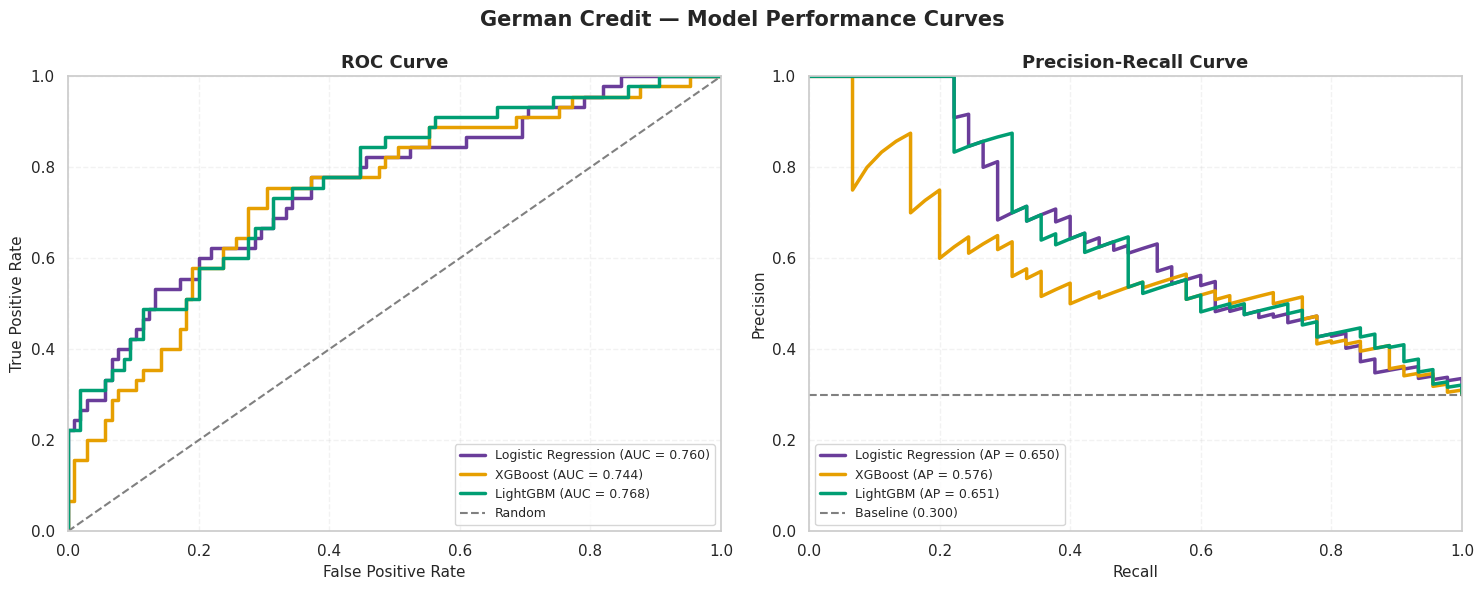

In [117]:
model_probs = {
    "Logistic Regression": lr_probs,
    "XGBoost": xgb_probs,
    "LightGBM": lgbm_probs
}

colors = {
    "Logistic Regression": "#6A3D9A",  
    "XGBoost": "#E69F01",              
    "LightGBM": "#009E73"              
}

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

fig.suptitle(
    "German Credit — Model Performance Curves",
    fontsize=15,
    fontweight="bold"
)

# Plot ROC and Precision-Recall curves
for name, probs in model_probs.items():

    # ROC Curve
    fpr, tpr, _ = roc_curve(y_test, probs)
    auc_score = roc_auc_score(y_test, probs)

    axes[0].plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc_score:.3f})",
        color=colors[name],
        linewidth=2.5
    )

    # Precision-Recall Curve
    precision, recall, _ = precision_recall_curve(y_test, probs)
    ap_score = average_precision_score(y_test, probs)

    axes[1].plot(
        recall,
        precision,
        label=f"{name} (AP = {ap_score:.3f})",
        color=colors[name],
        linewidth=2.5
    )

# ROC formatting
axes[0].plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    color="gray",
    label="Random"
)

axes[0].set_title("ROC Curve", fontsize=13, fontweight="bold")
axes[0].set_xlabel("False Positive Rate", fontsize=11)
axes[0].set_ylabel("True Positive Rate", fontsize=11)

axes[0].set_xlim(0, 1)
axes[0].set_ylim(0, 1)

axes[0].grid(
    True,
    linestyle="--",
    alpha=0.25
)

axes[0].legend(
    loc="lower right",
    fontsize=9,
    frameon=True
)

# Precision-Recall formatting
baseline = y_test.mean()

axes[1].axhline(
    y=baseline,
    linestyle="--",
    linewidth=1.5,
    color="gray",
    label=f"Baseline ({baseline:.3f})"
)

axes[1].set_title(
    "Precision-Recall Curve",
    fontsize=13,
    fontweight="bold"
)

axes[1].set_xlabel("Recall", fontsize=11)
axes[1].set_ylabel("Precision", fontsize=11)

axes[1].set_xlim(0, 1)
axes[1].set_ylim(0, 1)

axes[1].grid(
    True,
    linestyle="--",
    alpha=0.25
)

axes[1].legend(
    loc="lower left",
    fontsize=9,
    frameon=True
)

plt.tight_layout()
plt.show()

## 8. SHAP Explainability

SHAP (SHapley Additive exPlanations) is applied to all three models using the appropriate explainer:
- **TreeExplainer** for XGBoost and LightGBM — exact, polynomial-time computation
- **LinearExplainer** for Logistic Regression — exact for linear models

Three visualisation types are produced: global bar plots, beeswarm plot (best model), and individual waterfall plots for three case studies.

In [118]:
import shap

SHAP values are computed on the full test set for German Credit (150 rows — small enough to be exact).

In [119]:
# Logistic Regression — LinearExplainer (uses scaled data)
explainer_lr   = shap.LinearExplainer(best_lr, X_train_scaled)
shap_lr        = explainer_lr.shap_values(X_test_scaled)

In [120]:
# XGBoost — TreeExplainer (exact, fast)
explainer_xgb  = shap.TreeExplainer(best_xgb)
shap_xgb       = explainer_xgb.shap_values(X_test)

In [121]:
# LightGBM — TreeExplainer (exact, fast)
explainer_lgbm = shap.TreeExplainer(best_lgbm)
shap_lgbm      = explainer_lgbm.shap_values(X_test)

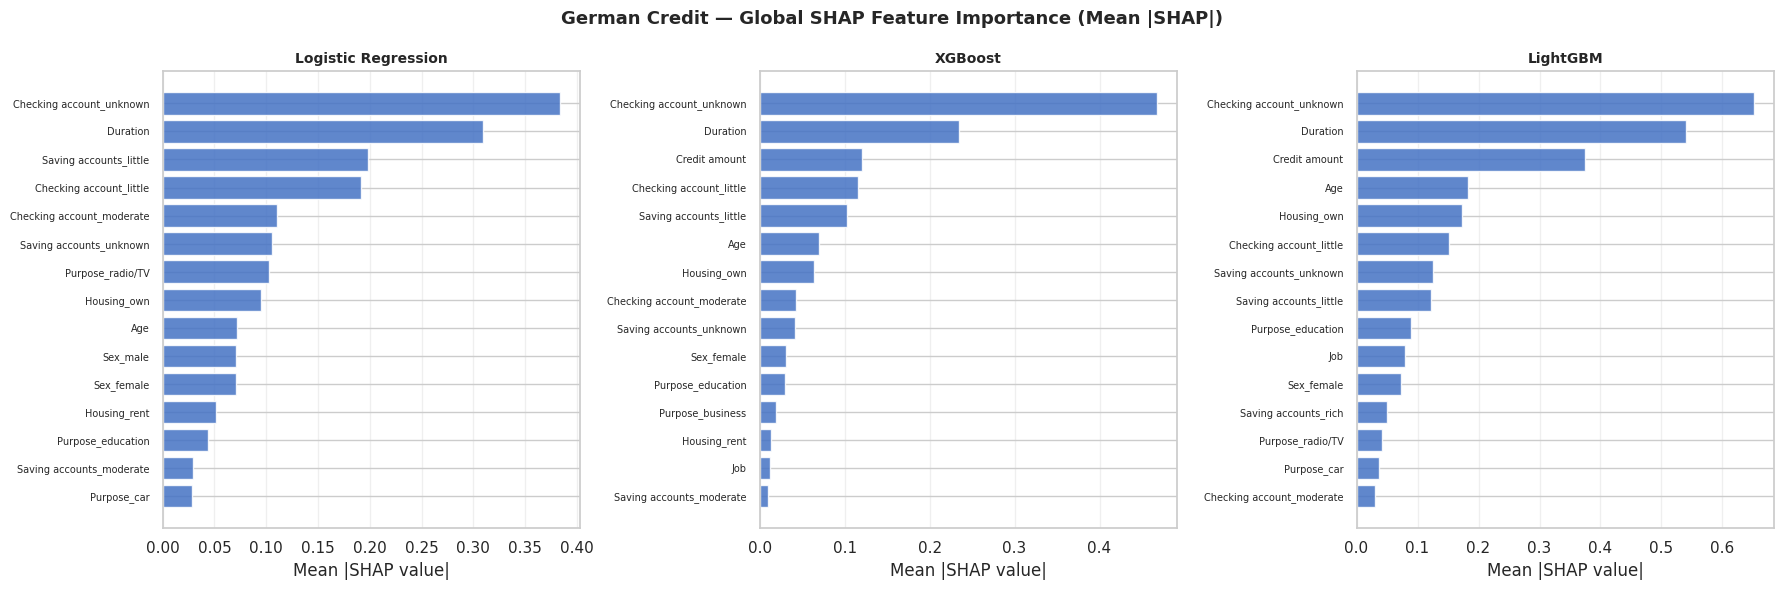

In [122]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle('German Credit — Global SHAP Feature Importance (Mean |SHAP|)',
             fontweight='bold', fontsize=13)

shap_data = [
    ('Logistic Regression', shap_lr,   X_test_scaled),
    ('XGBoost',             shap_xgb,  X_test),
    ('LightGBM',            shap_lgbm, X_test),
]

for ax, (name, sv, xdata) in zip(axes, shap_data):
    mean_abs = np.abs(sv).mean(axis=0)
    importance_df = pd.DataFrame({
        'feature': xdata.columns,
        'importance': mean_abs
    }).sort_values('importance', ascending=True).tail(15)

    ax.barh(importance_df['feature'], importance_df['importance'],
            color='#4472C4', alpha=0.85)
    ax.set_title(name, fontweight='bold', fontsize=10)
    ax.set_xlabel('Mean |SHAP value|')
    ax.tick_params(axis='y', labelsize=7)
    ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

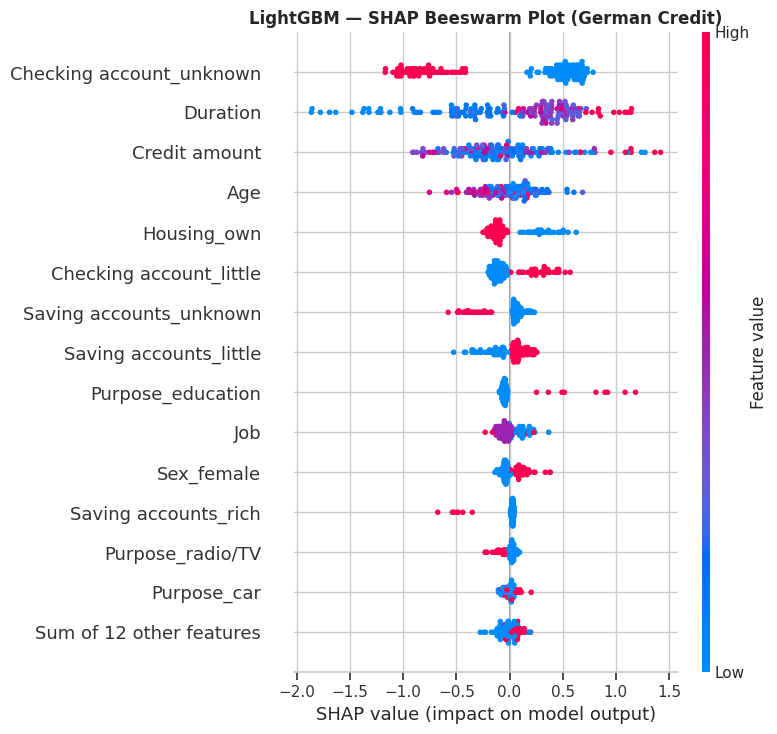

In [123]:
plt.figure(figsize=(10, 8))
# Use Explanation object for newer SHAP API
explanation_lgbm = shap.Explanation(
    values=shap_lgbm,
    base_values=explainer_lgbm.expected_value,
    data=X_test.values,
    feature_names=X_test.columns.tolist()
)
shap.plots.beeswarm(explanation_lgbm, max_display=15, show=False)
plt.title('LightGBM — SHAP Beeswarm Plot (German Credit)', fontweight='bold')
plt.tight_layout()
plt.show()

In [124]:
print("\nTop 10 features by mean |SHAP value|:")
print(f"\n{'Rank':<5} {'LightGBM':<30} {'XGBoost':<30} {'LR':<30}")
print("-" * 95)

def top_features(sv, cols, n=10):
    mean_abs = np.abs(sv).mean(axis=0)
    idx      = np.argsort(mean_abs)[::-1]
    return [cols[i] for i in idx[:n]]

lgbm_top = top_features(shap_lgbm, X_test.columns.tolist())
xgb_top  = top_features(shap_xgb,  X_test.columns.tolist())
lr_top   = top_features(shap_lr,   X_test_scaled.columns.tolist())

for i in range(10):
    print(f"{i+1:<5} {lgbm_top[i]:<30} {xgb_top[i]:<30} {lr_top[i]:<30}")


Top 10 features by mean |SHAP value|:

Rank  LightGBM                       XGBoost                        LR                            
-----------------------------------------------------------------------------------------------
1     Checking account_unknown       Checking account_unknown       Checking account_unknown      
2     Duration                       Duration                       Duration                      
3     Credit amount                  Credit amount                  Saving accounts_little        
4     Age                            Checking account_little        Checking account_little       
5     Housing_own                    Saving accounts_little         Checking account_moderate     
6     Checking account_little        Age                            Saving accounts_unknown       
7     Saving accounts_unknown        Housing_own                    Purpose_radio/TV              
8     Saving accounts_little         Checking account_moderate      Hous

Individual SHAP force plots — 3 case studies
- Case 1: Correctly classified low-risk (predicted 0, actual 0)
- Case 2: Correctly classified high-risk (predicted 1, actual 1)
- Case 3: Borderline case (probability closest to 0.5)


In [125]:
pred_probs = lgbm_probs
pred_class = lgbm_preds
y_test_arr = y_test.values

In [126]:
# Case 1 — correctly predicted non-default
mask_tn = (pred_class == 0) & (y_test_arr == 0)
if mask_tn.sum() > 0:
    idx_tn    = np.where(mask_tn)[0][0]
    case1_idx = idx_tn

In [127]:
# Case 2 — correctly predicted default
mask_tp = (pred_class == 1) & (y_test_arr == 1)
if mask_tp.sum() > 0:
    idx_tp    = np.where(mask_tp)[0][0]
    case2_idx = idx_tp

In [128]:
# Case 3 — most borderline (probability closest to 0.5)
case3_idx = np.argmin(np.abs(pred_probs - 0.5))

In [129]:
cases = {
    'Case 1 — Correctly Classified Non-Default': case1_idx,
    'Case 2 — Correctly Classified Default':     case2_idx,
    'Case 3 — Borderline (prob closest to 0.5)': case3_idx,
}


  Case 1 — Correctly Classified Non-Default
    Predicted probability: 0.054 | Actual: Non-Default


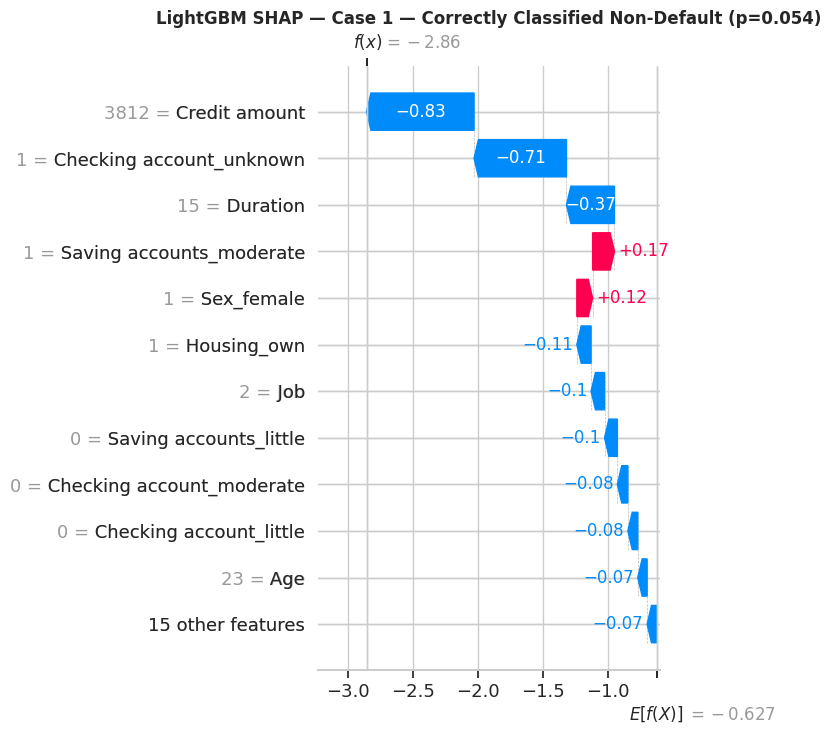


  Case 2 — Correctly Classified Default
    Predicted probability: 0.851 | Actual: Default


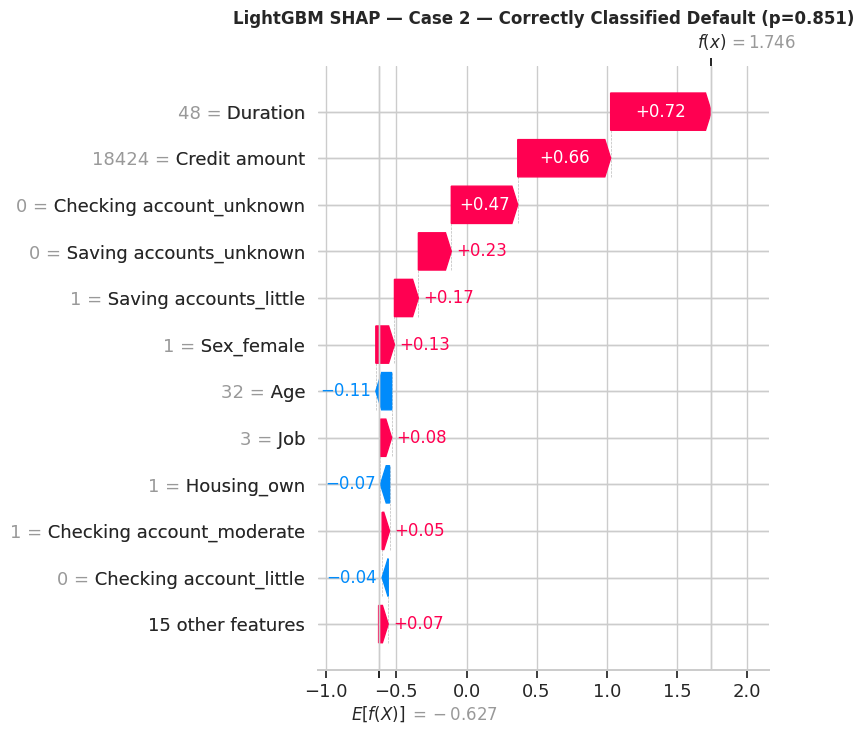


  Case 3 — Borderline (prob closest to 0.5)
    Predicted probability: 0.494 | Actual: Non-Default


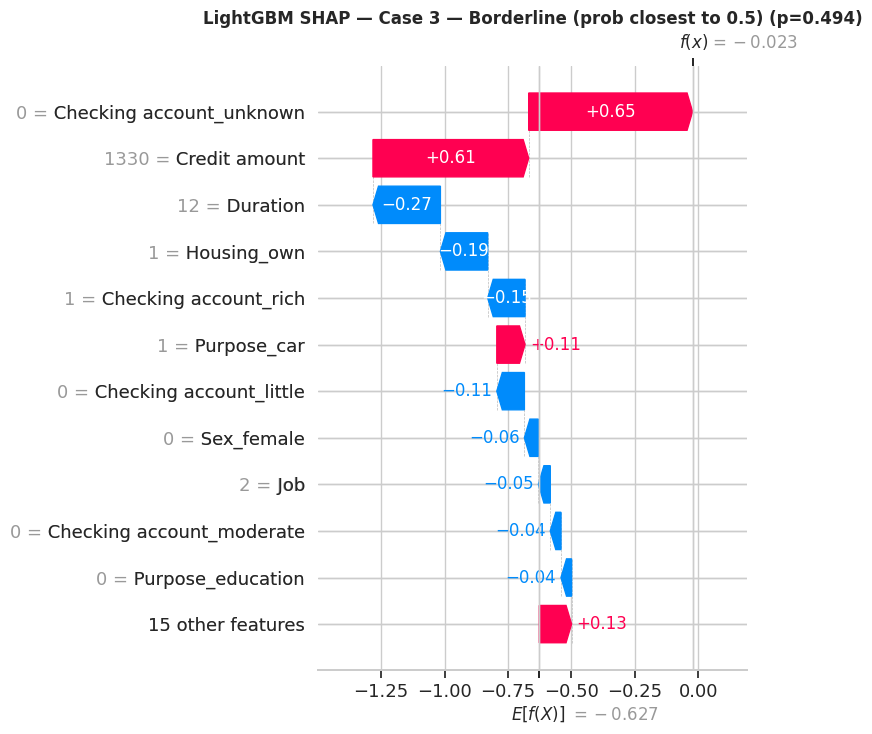

In [130]:
for case_name, idx in cases.items():
    prob  = pred_probs[idx]
    actual = y_test_arr[idx]
    print(f"\n  {case_name}")
    print(f"    Predicted probability: {prob:.3f} | Actual: {'Default' if actual==1 else 'Non-Default'}")

    # Waterfall plot for this individual
    exp_single = shap.Explanation(
        values=shap_lgbm[idx],
        base_values=explainer_lgbm.expected_value,
        data=X_test.iloc[idx].values,
        feature_names=X_test.columns.tolist()
    )
    plt.figure(figsize=(10, 6))
    shap.plots.waterfall(exp_single, max_display=12, show=False)
    safe_name = case_name.split('—')[0].strip().replace(' ', '_').lower()
    plt.title(f'LightGBM SHAP — {case_name} (p={prob:.3f})', fontweight='bold')
    plt.tight_layout()
    plt.show()

## 9. DiCE Counterfactual Explanations

DiCE (Diverse Counterfactual Explanations; Mothilal et al., 2020) generates actionable recourse scenarios for rejected applicants — answering *'what would need to change for this application to be approved?'*

**Immutable features:** Age and Sex cannot be changed by the applicant and are locked.
**Model used:** LightGBM (best-performing model).
**Method:** `random` — appropriate for the small German Credit test set.

In [131]:
import dice_ml
from dice_ml import Dice

In [132]:
# DiCE uses the original (pre-SMOTE) training data
# SMOTE creates synthetic points that may not reflect realistic feature combinations
# Using original X_train preserves the real data distribution for counterfactual generation
# train_df_dice = X_train.copy()
# train_df_dice['Risk'] = y_train.values

X_orig_g = g_df.drop('Risk', axis=1)
y_orig_g = g_df['Risk']

In [133]:
# Same split to get aligned training data
X_tr_g, X_tmp_g, y_tr_g, _ = train_test_split(X_orig_g, y_orig_g,
                                                 test_size=0.30,
                                                 random_state=42,
                                                 stratify=y_orig_g)
X_val_g, X_te_g, _, y_te_g = train_test_split(X_tmp_g, _,
                                                test_size=0.50,
                                                random_state=42,
                                                stratify=_)

In [134]:
scale_pos_weight_g = (y_tr_g == 0).sum() / (y_tr_g == 1).sum()

In [135]:
preprocessor = ColumnTransformer(transformers=[
    ('num', 'passthrough', numerical_features),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features),
])

pipe_lgbm = Pipeline([
    ('prep', preprocessor),
    ('clf',  LGBMClassifier(
        **study_lgbm.best_params,
        scale_pos_weight = scale_pos_weight_g,
        random_state=42,
        n_jobs=-1,
        verbose=-1,
    ))
])
pipe_lgbm.fit(X_tr_g, y_tr_g)

,steps,"[('prep', ...), ('clf', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [136]:
# Immutable: features the applicant cannot realistically change
immutable_features = ['Age', 'Sex_male', 'Sex_female']

In [137]:
train_dice_g = X_tr_g.copy() # talk about only usibg a sample and it not working
train_dice_g['Risk'] = y_tr_g

dice_data = dice_ml.Data(
    dataframe=train_dice_g,
    continuous_features=numerical_features,
    categorical_features=categorical_features,
    outcome_name='Risk'
)

dice_model = dice_ml.Model(
    model=pipe_lgbm,
    backend='sklearn',
    model_type='classifier'
)

dice_explainer = Dice(dice_data, dice_model, method='random')

In [138]:
# Predict test set
threshold = thresh_lgbm

test_probs = pipe_lgbm.predict_proba(X_te_g)[:, 1]
rejected = np.where(test_probs >= threshold)[0]

print(f"\nRejected applicants in test set: {len(rejected):,}")
print("Generating counterfactuals for first 5:")


# Only use features that actually exist
immutable = [c for c in immutable_features if c in X_te_g.columns]

# Everything else can potentially vary
vary_cols = [c for c in X_te_g.columns if c not in immutable]

print(f"Immutable features: {len(immutable)}")
print(f"Features allowed to vary: {len(vary_cols)}")


# Generate counterfactuals

results_dice = []
valid_count = 0

n_to_test = min(5, len(rejected))

for i, idx in enumerate(rejected[:n_to_test]):

    query = X_te_g.iloc[[idx]].copy()
    orig_prob = pipe_lgbm.predict_proba(query)[0, 1]

    try:
        cf = dice_explainer.generate_counterfactuals(
            query,
            total_CFs=3,
            desired_class=0,
            features_to_vary=vary_cols,
        )

        cf_df = cf.cf_examples_list[0].final_cfs_df

        if cf_df is not None and not cf_df.empty:

            valid_count += 1

            # Display changes for first 3 applicants
            if i < 3:
                print(f"\nApplicant {idx} (p_default={orig_prob:.3f})")
                print("Changes needed for approval:")

                original = query.iloc[0]
                counterfactual = cf_df.iloc[0]

                changes = []

                for col in vary_cols:
                    if col in cf_df.columns:
                        old = original[col]
                        new = counterfactual[col]

                        if old != new:
                            changes.append((col, old, new))

                if changes:
                    for col, old, new in changes:
                        print(f"  {col}: {old} → {new}")
                else:
                    print("  No feature changes found.")

            results_dice.append({
                'applicant_idx': idx,
                'original_prob': round(orig_prob, 3),
                'n_valid_cfs': len(cf_df)
            })

    except Exception as e:
        print(f"Applicant {idx}: failed — {str(e)[:150]}")


# Summary

validity_rate = valid_count / n_to_test if n_to_test > 0 else 0

print(
    f"\nDiCE validity rate: "
    f"{valid_count}/{n_to_test} = {validity_rate:.0%}"
)

print(
    f"Proposal target: ≥90% — "
    f"{'MET' if validity_rate >= 0.90 else 'NOT MET'}")


Rejected applicants in test set: 43
Generating counterfactuals for first 5:
Immutable features: 1
Features allowed to vary: 8


100%|██████████| 1/1 [00:00<00:00,  4.73it/s]



Applicant 2 (p_default=0.851)
Changes needed for approval:
  Saving accounts: little → unknown
  Checking account: moderate → rich


100%|██████████| 1/1 [00:00<00:00,  4.79it/s]



Applicant 4 (p_default=0.837)
Changes needed for approval:
  Housing: rent → own
  Saving accounts: little → unknown


100%|██████████| 1/1 [00:00<00:00,  4.66it/s]



Applicant 15 (p_default=0.745)
Changes needed for approval:
  Sex: male → female
  Duration: 24 → 14


100%|██████████| 1/1 [00:00<00:00,  4.82it/s]


DiCE validity rate: 5/5 = 100%
Proposal target: ≥90% — MET


## 10. Fairness Audit

Fairness is evaluated using **Microsoft Fairlearn** across two sensitive attributes:
- **Age** (binned: Under 25 / 25-35 / 35-45 / 45-55 / 55–65 / Over 65)
- **Sex** (Male / Female)

Three metrics are computed per model per attribute:
- **Demographic Parity Difference (DPD)** — difference in prediction rates (threshold < 0.10)
- **Equalised Odds Difference (EOD)** — difference in TPR/FPR (threshold < 0.10)
- **Disparate Impact Ratio (DIR)** — ratio of approval rates (threshold > 0.80, the '80% rule')

In [139]:
model_preds_dict = {
    'Logistic Regression': lr_preds,
    'XGBoost':             xgb_preds,
    'LightGBM':            lgbm_preds,
}

In [140]:
# Derive sensitive features directly from X_test (post-encoding)
# Age: still a numerical column in X_test
sensitive_age_test = g_df.loc[X_test.index, 'Age']
sensitive_sex_test = g_df.loc[X_test.index, 'Sex']

In [141]:
sensitive_age_binned = pd.cut(
    sensitive_age_test,
    bins=[0, 25, 35, 45, 55, 65, 100],
    labels=['<25', '25-35', '35-45', '45-55', '55-65', '65+']
)

In [142]:
def compute_fairness(y_true, y_pred, sensitive, model_name, feature_name):
    dpd = demographic_parity_difference(
        y_true=y_true, y_pred=y_pred,
        sensitive_features=sensitive
    )
    eod = equalized_odds_difference(
        y_true=y_true, y_pred=y_pred,
        sensitive_features=sensitive
    )
    dir_score = demographic_parity_ratio(
        y_true=y_true, y_pred=y_pred,
        sensitive_features=sensitive
    )
    return {
        'Model':                        model_name,
        'Sensitive Feature':            feature_name,
        'Demographic Parity Diff':      round(abs(dpd), 4),
        'Equalised Odds Diff':          round(eod,      4),
        'Disparate Impact Ratio':       round(dir_score, 4),
        'DPD Pass (<0.10)':             'PASS' if abs(dpd) < 0.10 else 'FAIL',
        'EOD Pass (<0.10)':             'PASS' if eod      < 0.10 else 'FAIL',
        'DIR Pass (>0.80)':             'PASS' if dir_score >= 0.80 else 'FAIL',
    }

In [143]:
fairness_results = []
print("\nFairness Metrics — Age Groups:")

for model_name, y_pred in model_preds_dict.items():
    row = compute_fairness(
        y_test.values, y_pred,
        sensitive_age_binned.values,
        model_name, 'Age Group'
    )
    fairness_results.append(row)
    print(f"\n  {model_name}:")
    print(f"    Demographic Parity Difference: {row['Demographic Parity Diff']:.4f} [{row['DPD Pass (<0.10)']}]")
    print(f"    Equalised Odds Difference:     {row['Equalised Odds Diff']:.4f} [{row['EOD Pass (<0.10)']}]")
    print(f"    Disparate Impact Ratio:        {row['Disparate Impact Ratio']:.4f} [{row['DIR Pass (>0.80)']}]")

fairness_df_age = pd.DataFrame(fairness_results)


Fairness Metrics — Age Groups:

  Logistic Regression:
    Demographic Parity Difference: 0.3125 [FAIL]
    Equalised Odds Difference:     0.5000 [FAIL]
    Disparate Impact Ratio:        0.0000 [FAIL]

  XGBoost:
    Demographic Parity Difference: 0.3333 [FAIL]
    Equalised Odds Difference:     1.0000 [FAIL]
    Disparate Impact Ratio:        0.4444 [FAIL]

  LightGBM:
    Demographic Parity Difference: 0.3016 [FAIL]
    Equalised Odds Difference:     1.0000 [FAIL]
    Disparate Impact Ratio:        0.3214 [FAIL]


In [144]:
print("\nGroup-level breakdown — LightGBM vs Age Group:")
mf = MetricFrame(
    metrics={
        'accuracy':       accuracy_score,
        'precision':      lambda yt, yp: precision_score(yt, yp, zero_division=0),
        'recall':         recall_score,
        'selection_rate': lambda yt, yp: float(np.mean(yp)),
    },
    y_true=y_test.values,
    y_pred=lgbm_preds,
    sensitive_features=sensitive_age_binned.values
)
print(mf.by_group.to_string())


Group-level breakdown — LightGBM vs Age Group:
                     accuracy  precision    recall  selection_rate
sensitive_feature_0                                               
25-35                0.759259   0.600000  0.562500        0.277778
35-45                0.800000   0.600000  0.375000        0.142857
45-55                0.866667   0.666667  0.666667        0.200000
55-65                0.777778   0.500000  1.000000        0.444444
65+                  0.400000   0.000000  0.000000        0.400000
<25                  0.531250   0.500000  0.466667        0.437500


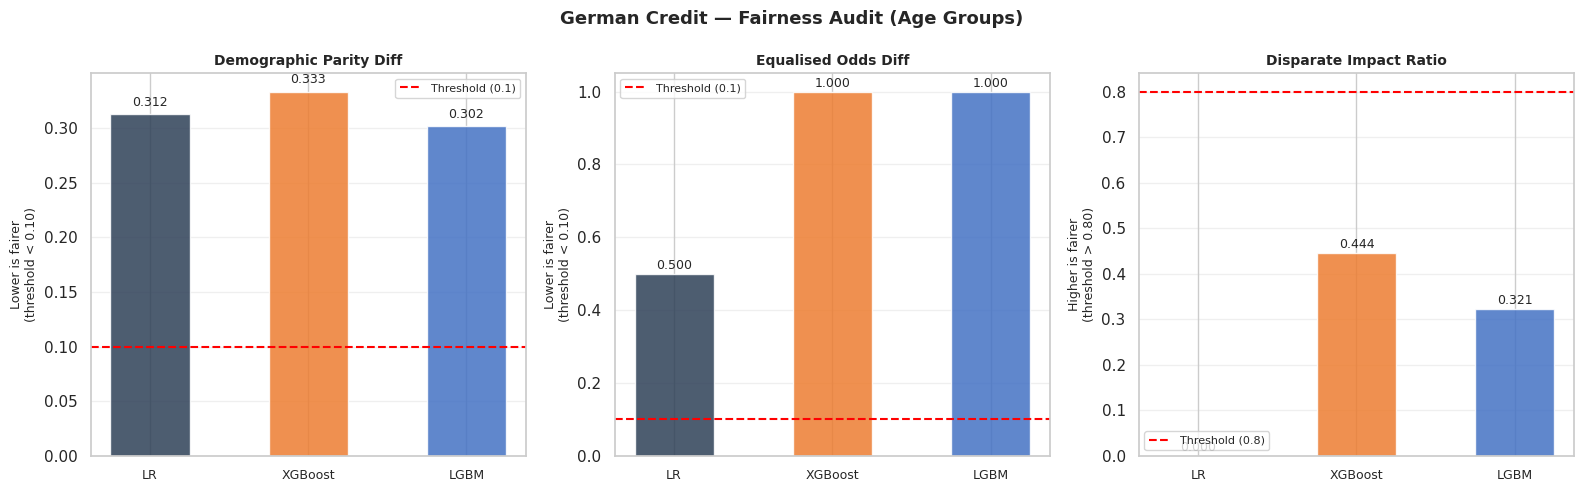

In [145]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('German Credit — Fairness Audit (Age Groups)',
             fontweight='bold', fontsize=13)

metrics_plot = [
    ('Demographic Parity Diff',  0.10, 'Lower is fairer\n(threshold < 0.10)'),
    ('Equalised Odds Diff',      0.10, 'Lower is fairer\n(threshold < 0.10)'),
    ('Disparate Impact Ratio',   0.80, 'Higher is fairer\n(threshold > 0.80)'),
]

model_list = ['Logistic Regression', 'XGBoost', 'LightGBM']
x          = np.arange(len(model_list))
bar_colors = ['#2E4057', '#ED7D31', '#4472C4']

for ax, (metric, threshold, ylabel) in zip(axes, metrics_plot):
    vals = fairness_df_age[fairness_df_age['Sensitive Feature']=='Age Group'][metric].values
    bars = ax.bar(x, vals, color=bar_colors, alpha=0.85, width=0.5)
    ax.axhline(y=threshold, color='red', linestyle='--', lw=1.5,
               label=f'Threshold ({threshold})')
    ax.set_xticks(x)
    ax.set_xticklabels(['LR', 'XGBoost', 'LGBM'], fontsize=9)
    ax.set_title(metric, fontweight='bold', fontsize=10)
    ax.set_ylabel(ylabel, fontsize=9)
    ax.legend(fontsize=8)
    ax.grid(axis='y', alpha=0.3)
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
                f'{val:.3f}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

In [146]:
fairness_results = []
print("\nFairness Metrics — Sex:")

for model_name, y_pred in model_preds_dict.items():
    row = compute_fairness(
        y_test.values, y_pred,
        sensitive_sex_test.values,
        model_name, 'Sex'
    )
    fairness_results.append(row)
    print(f"\n  {model_name}:")
    print(f"    Demographic Parity Difference: {row['Demographic Parity Diff']:.4f} [{row['DPD Pass (<0.10)']}]")
    print(f"    Equalised Odds Difference:     {row['Equalised Odds Diff']:.4f} [{row['EOD Pass (<0.10)']}]")
    print(f"    Disparate Impact Ratio:        {row['Disparate Impact Ratio']:.4f} [{row['DIR Pass (>0.80)']}]")

fairness_df_sex = pd.DataFrame(fairness_results)



Fairness Metrics — Sex:

  Logistic Regression:
    Demographic Parity Difference: 0.0602 [PASS]
    Equalised Odds Difference:     0.0714 [PASS]
    Disparate Impact Ratio:        0.6750 [FAIL]

  XGBoost:
    Demographic Parity Difference: 0.0648 [PASS]
    Equalised Odds Difference:     0.0587 [PASS]
    Disparate Impact Ratio:        0.8654 [PASS]

  LightGBM:
    Demographic Parity Difference: 0.0440 [PASS]
    Equalised Odds Difference:     0.2085 [FAIL]
    Disparate Impact Ratio:        0.8603 [PASS]


In [147]:
mf = MetricFrame(
    metrics={
        'accuracy':       accuracy_score,
        'precision':      lambda yt, yp: precision_score(yt, yp, zero_division=0),
        'recall':         recall_score,
        'selection_rate': lambda yt, yp: float(np.mean(yp)),
    },
    y_true=y_test.values,
    y_pred=lgbm_preds,
    sensitive_features=sensitive_sex_test.values
)
print(mf.by_group.to_string())

                     accuracy  precision    recall  selection_rate
sensitive_feature_0                                               
female               0.777778   0.705882  0.631579        0.314815
male                 0.687500   0.423077  0.423077        0.270833


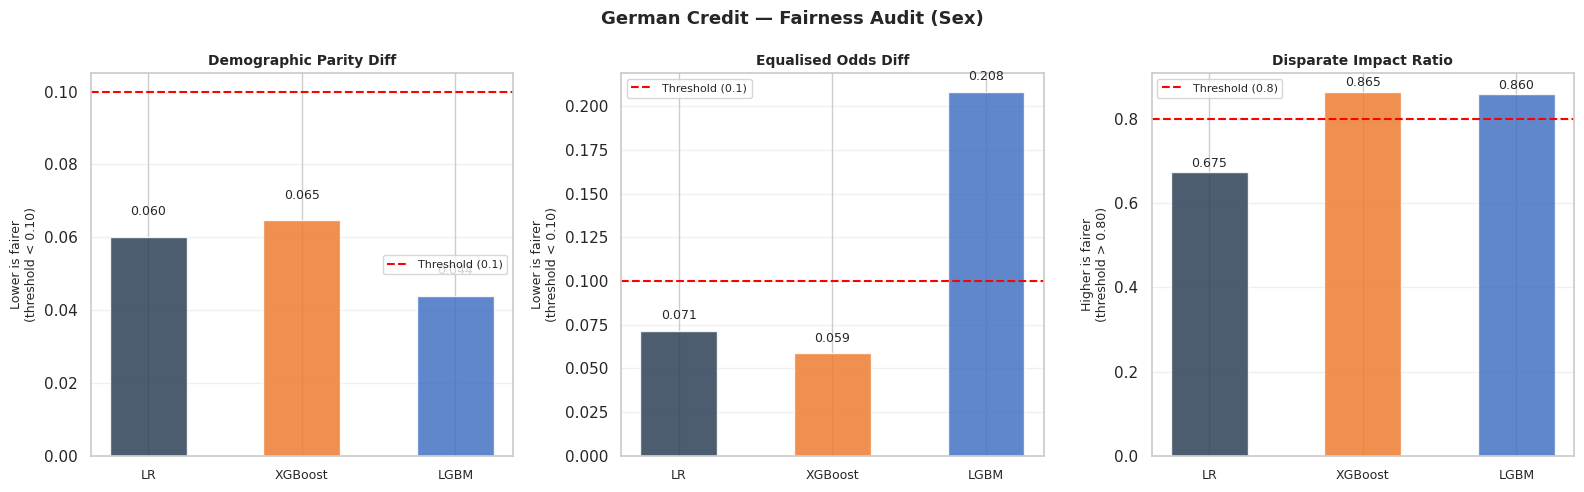

In [148]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('German Credit — Fairness Audit (Sex)',
             fontweight='bold', fontsize=13)

metrics_plot = [
    ('Demographic Parity Diff',  0.10, 'Lower is fairer\n(threshold < 0.10)'),
    ('Equalised Odds Diff',      0.10, 'Lower is fairer\n(threshold < 0.10)'),
    ('Disparate Impact Ratio',   0.80, 'Higher is fairer\n(threshold > 0.80)'),
]

model_list = ['Logistic Regression', 'XGBoost', 'LightGBM']
x          = np.arange(len(model_list))
bar_colors = ['#2E4057', '#ED7D31', '#4472C4']

for ax, (metric, threshold, ylabel) in zip(axes, metrics_plot):
    vals = fairness_df_sex[fairness_df_sex['Sensitive Feature']=='Sex'][metric].values
    bars = ax.bar(x, vals, color=bar_colors, alpha=0.85, width=0.5)
    ax.axhline(y=threshold, color='red', linestyle='--', lw=1.5,
               label=f'Threshold ({threshold})')
    ax.set_xticks(x)
    ax.set_xticklabels(['LR', 'XGBoost', 'LGBM'], fontsize=9)
    ax.set_title(metric, fontweight='bold', fontsize=10)
    ax.set_ylabel(ylabel, fontsize=9)
    ax.legend(fontsize=8)
    ax.grid(axis='y', alpha=0.3)
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
                f'{val:.3f}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

# Home Credit Pipeline

## 1. Imports & Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import os
import time
import re

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    f1_score, brier_score_loss,
    roc_curve, precision_recall_curve, accuracy_score
)
from scipy import stats
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from fairlearn.metrics import (
    demographic_parity_difference,
    equalized_odds_difference,
    demographic_parity_ratio,
    MetricFrame,
)
import optuna
import shap
import dice_ml
from dice_ml import Dice

warnings.filterwarnings('ignore')
os.makedirs('outputs_hc', exist_ok=True)
optuna.logging.set_verbosity(optuna.logging.WARNING)

## 2. Data Loading and Preprocessing

### Data loading

In [2]:
t0 = time.time()
df = pd.read_csv('application_train.csv')
print(f"\nLoaded: {df.shape[0]:,} rows × {df.shape[1]} columns ({time.time()-t0:.1f}s)")
print(f"Default rate: {df['TARGET'].mean():.2%} ({df['TARGET'].sum():,} defaults)")


Loaded: 307,511 rows × 122 columns (4.8s)
Default rate: 8.07% (24,825 defaults)


In [3]:
df.head()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 307511 entries, 0 to 307510
Columns: 122 entries, SK_ID_CURR to AMT_REQ_CREDIT_BUREAU_YEAR
dtypes: float64(65), int64(41), object(16)
memory usage: 286.2+ MB


In [5]:
df = df.drop('SK_ID_CURR', axis=1)

In [6]:
df['TARGET'].value_counts()

TARGET
0    282686
1     24825
Name: count, dtype: int64

In [7]:
nulls = df.isnull().sum()
if nulls[nulls > 0].shape[0] > 0:
    print(f"\nColumns with missing values ({nulls[nulls > 0].shape[0]}):")
    print(nulls[nulls > 0])


Columns with missing values (67):
AMT_ANNUITY                       12
AMT_GOODS_PRICE                  278
NAME_TYPE_SUITE                 1292
OWN_CAR_AGE                   202929
OCCUPATION_TYPE                96391
                               ...  
AMT_REQ_CREDIT_BUREAU_DAY      41519
AMT_REQ_CREDIT_BUREAU_WEEK     41519
AMT_REQ_CREDIT_BUREAU_MON      41519
AMT_REQ_CREDIT_BUREAU_QRT      41519
AMT_REQ_CREDIT_BUREAU_YEAR     41519
Length: 67, dtype: int64


In [8]:
missing_pct = df.isnull().sum() / len(df) * 100
cols_to_drop_missing = missing_pct[missing_pct > 40].index.tolist()
cols_to_drop_missing = [c for c in cols_to_drop_missing if c != 'TARGET']
df = df.drop(columns=cols_to_drop_missing)
print(f"\n40% missing filter: dropped {len(cols_to_drop_missing)} features")
print(f"Remaining features: {df.shape[1]-1} (excl. TARGET)")


40% missing filter: dropped 49 features
Remaining features: 71 (excl. TARGET)


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 307511 entries, 0 to 307510
Data columns (total 72 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   TARGET                       307511 non-null  int64  
 1   NAME_CONTRACT_TYPE           307511 non-null  object 
 2   CODE_GENDER                  307511 non-null  object 
 3   FLAG_OWN_CAR                 307511 non-null  object 
 4   FLAG_OWN_REALTY              307511 non-null  object 
 5   CNT_CHILDREN                 307511 non-null  int64  
 6   AMT_INCOME_TOTAL             307511 non-null  float64
 7   AMT_CREDIT                   307511 non-null  float64
 8   AMT_ANNUITY                  307499 non-null  float64
 9   AMT_GOODS_PRICE              307233 non-null  float64
 10  NAME_TYPE_SUITE              306219 non-null  object 
 11  NAME_INCOME_TYPE             307511 non-null  object 
 12  NAME_EDUCATION_TYPE          307511 non-null  object 
 13 

In [10]:
nulls = df.isnull().sum().sort_values(ascending=False)
if nulls[nulls > 0].shape[0] > 0:
    print(f"\nColumns with missing values ({nulls[nulls > 0].shape[0]}):")
    print(nulls[nulls > 0])


Columns with missing values (18):
OCCUPATION_TYPE               96391
EXT_SOURCE_3                  60965
AMT_REQ_CREDIT_BUREAU_DAY     41519
AMT_REQ_CREDIT_BUREAU_HOUR    41519
AMT_REQ_CREDIT_BUREAU_YEAR    41519
AMT_REQ_CREDIT_BUREAU_WEEK    41519
AMT_REQ_CREDIT_BUREAU_QRT     41519
AMT_REQ_CREDIT_BUREAU_MON     41519
NAME_TYPE_SUITE                1292
OBS_30_CNT_SOCIAL_CIRCLE       1021
DEF_30_CNT_SOCIAL_CIRCLE       1021
OBS_60_CNT_SOCIAL_CIRCLE       1021
DEF_60_CNT_SOCIAL_CIRCLE       1021
EXT_SOURCE_2                    660
AMT_GOODS_PRICE                 278
AMT_ANNUITY                      12
CNT_FAM_MEMBERS                   2
DAYS_LAST_PHONE_CHANGE            1
dtype: int64


In [11]:
col_num  = df.select_dtypes(include=['int64','float64']).columns.tolist()
col_cat  = df.select_dtypes(include=['object']).columns.tolist()

In [12]:
binary_cols = [
    col for col in df.columns
    if set(df[col].dropna().unique()).issubset({0, 1}) and col != 'TARGET'
]
for col in binary_cols:
    counts = df[col].value_counts().sort_index()
    print(f"{col}: 0 = {counts.get(0, 0)}, 1 = {counts.get(1, 0)}")

FLAG_MOBIL: 0 = 1, 1 = 307510
FLAG_EMP_PHONE: 0 = 55386, 1 = 252125
FLAG_WORK_PHONE: 0 = 246203, 1 = 61308
FLAG_CONT_MOBILE: 0 = 574, 1 = 306937
FLAG_PHONE: 0 = 221080, 1 = 86431
FLAG_EMAIL: 0 = 290069, 1 = 17442
REG_REGION_NOT_LIVE_REGION: 0 = 302854, 1 = 4657
REG_REGION_NOT_WORK_REGION: 0 = 291899, 1 = 15612
LIVE_REGION_NOT_WORK_REGION: 0 = 295008, 1 = 12503
REG_CITY_NOT_LIVE_CITY: 0 = 283472, 1 = 24039
REG_CITY_NOT_WORK_CITY: 0 = 236644, 1 = 70867
LIVE_CITY_NOT_WORK_CITY: 0 = 252296, 1 = 55215
FLAG_DOCUMENT_2: 0 = 307498, 1 = 13
FLAG_DOCUMENT_3: 0 = 89171, 1 = 218340
FLAG_DOCUMENT_4: 0 = 307486, 1 = 25
FLAG_DOCUMENT_5: 0 = 302863, 1 = 4648
FLAG_DOCUMENT_6: 0 = 280433, 1 = 27078
FLAG_DOCUMENT_7: 0 = 307452, 1 = 59
FLAG_DOCUMENT_8: 0 = 282487, 1 = 25024
FLAG_DOCUMENT_9: 0 = 306313, 1 = 1198
FLAG_DOCUMENT_10: 0 = 307504, 1 = 7
FLAG_DOCUMENT_11: 0 = 306308, 1 = 1203
FLAG_DOCUMENT_12: 0 = 307509, 1 = 2
FLAG_DOCUMENT_13: 0 = 306427, 1 = 1084
FLAG_DOCUMENT_14: 0 = 306608, 1 = 903
FLAG_DOCU

Some of these columns do not add any value as they have a near zero variance. These features are the ones that have a more than 99% for one value: 

FLAG_MOBIL: 0 = 1, 1 = 307510;
FLAG_DOCUMENT_2: 0 = 307498, 1 = 13; 
FLAG_DOCUMENT_4: 0 = 307486, 1 = 25;
FLAG_DOCUMENT_7: 0 = 307452, 1 = 59;
FLAG_DOCUMENT_10: 0 = 307504, 1 = 7;
FLAG_DOCUMENT_12: 0 = 307509, 1 = 2;
FLAG_DOCUMENT_17: 0 = 307429, 1 = 82;
FLAG_DOCUMENT_19: 0 = 307328, 1 = 183;
FLAG_DOCUMENT_20: 0 = 307355, 1 = 156;
FLAG_DOCUMENT_21: 0 = 307408, 1 = 103;

Therefore, we are going to drop them since they do not provide any information.

In [13]:
nzv_cols = [
    'FLAG_MOBIL',          # 100% one value
    'FLAG_DOCUMENT_2',     # 99.996% one value
    'FLAG_DOCUMENT_4',     # 99.992% one value
    'FLAG_DOCUMENT_7',     # 99.981% one value
    'FLAG_DOCUMENT_10',    # 99.998% one value
    'FLAG_DOCUMENT_12',    # 99.999% one value
    'FLAG_DOCUMENT_17',    # 99.973% one value
    'FLAG_DOCUMENT_19',    # 99.940% one value
    'FLAG_DOCUMENT_20',    # 99.949% one value
    'FLAG_DOCUMENT_21',    # 99.967% one value
]
nzv_cols = [c for c in nzv_cols if c in df.columns]
df = df.drop(columns=nzv_cols)
print(f"Near-zero variance filter: dropped {len(nzv_cols)} features")
print(f"Working feature set: {df.shape[1]-1} features")

Near-zero variance filter: dropped 10 features
Working feature set: 61 features


In [14]:
for col in col_cat:
    if col in df.columns:
        n_unique = df[col].nunique()
        print(f"{col}: {n_unique} unique values")

NAME_CONTRACT_TYPE: 2 unique values
CODE_GENDER: 3 unique values
FLAG_OWN_CAR: 2 unique values
FLAG_OWN_REALTY: 2 unique values
NAME_TYPE_SUITE: 7 unique values
NAME_INCOME_TYPE: 8 unique values
NAME_EDUCATION_TYPE: 5 unique values
NAME_FAMILY_STATUS: 6 unique values
NAME_HOUSING_TYPE: 6 unique values
OCCUPATION_TYPE: 18 unique values
WEEKDAY_APPR_PROCESS_START: 7 unique values
ORGANIZATION_TYPE: 58 unique values


### Feature Engineering

In [15]:
df['AGE_YEARS']       = (df['DAYS_BIRTH'] / -365.25).round(0).astype(int)
df['DAYS_BIRTH']      = df['DAYS_BIRTH'].abs()   # keep as positive days too

In [16]:
def get_age_label(days_birth):
    """ Return the age group label (int). """
    age_years = -days_birth / 365
    if age_years < 25: return 1
    elif age_years < 35: return 2
    elif age_years < 45: return 3
    elif age_years < 55: return 4
    elif age_years < 65: return 5
    elif age_years >= 65: return 6
    else: return 0

df['AGE_RANGE'] = df['DAYS_BIRTH'].apply(lambda x: get_age_label(x))

With the feature DAYS_EMPLOYED: 365243 is a sentinel value for unemployed applicants. We will replace it with with nan and then it will get emputed using the median

In [17]:
df['DAYS_EMPLOYED'] = df['DAYS_EMPLOYED'].replace(365243, np.nan)
df['DAYS_EMPLOYED'] = df['DAYS_EMPLOYED'].abs()  # keep as positive days too
df['EMPLOYED_YEARS'] = (df['DAYS_EMPLOYED'] / 365.25)
df['YEARS_TO_65'] = 65 - df['AGE_YEARS'] # Years left of work

In [18]:
df['DAYS_ID_PUBLISH'] = df['DAYS_ID_PUBLISH'].abs()  # keep as positive days too
df['DAYS_REGISTRATION'] = df['DAYS_REGISTRATION'].abs()  # keep as positive days too
df['DAYS_LAST_PHONE_CHANGE'] = df['DAYS_LAST_PHONE_CHANGE'].abs()  # keep as positive days too

In [19]:
# Engineered financial ratios — meaningful for credit risk
df['CREDIT_TO_INCOME_RATIO']  = df['AMT_CREDIT'] / (df['AMT_INCOME_TOTAL'] + 1) # Adding 1 to avoid division by zero
df['ANNUITY_TO_INCOME_RATIO'] = df['AMT_ANNUITY'] / (df['AMT_INCOME_TOTAL'] + 1)
df['CREDIT_TO_GOODS_RATIO']   = df['AMT_CREDIT'] / (df['AMT_GOODS_PRICE'] + 1) # Avoid division by zero

df['ANNUITY_TO_CREDIT_RATIO'] = df['AMT_ANNUITY'] / (df['AMT_CREDIT'] + 1)
df['DOWN_PAYMENT_RATIO'] = ((df['AMT_GOODS_PRICE'] - df['AMT_CREDIT']) / (df['AMT_GOODS_PRICE'] + 1))
df['CREDIT_MINUS_INCOME'] = df['AMT_CREDIT'] - df['AMT_INCOME_TOTAL']
df['INCOME_FAMILY_INTERACTION'] = df['AMT_INCOME_TOTAL'] * df['CNT_FAM_MEMBERS']

df['INCOME_AFTER_ANNUITY'] = df['AMT_INCOME_TOTAL'] - df['AMT_ANNUITY']

In [20]:
df['LOG_INCOME'] = np.log1p(df['AMT_INCOME_TOTAL'])
df['LOG_CREDIT'] = np.log1p(df['AMT_CREDIT'])
df['LOG_ANNUITY'] = np.log1p(df['AMT_ANNUITY'])
df['LOG_GOODS_PRICE'] = np.log1p(df['AMT_GOODS_PRICE'])

In [21]:
df['DAYS_EMPLOYED_B'] = df['DAYS_EMPLOYED'] / (df['DAYS_BIRTH'] + 1)

df['INCOME_PER_FAMILY_MEMBER'] = df['AMT_INCOME_TOTAL'] / (df['CNT_FAM_MEMBERS'] + 1)
df['INCOME_PER_CHILD'] = df['AMT_INCOME_TOTAL'] / (df['CNT_CHILDREN'] + 1)
df['INCOME_PER_ADULT'] = df['AMT_INCOME_TOTAL'] / ((df['CNT_FAM_MEMBERS'] - df['CNT_CHILDREN']).clip(lower=1))

df['PAYMENT_RATE'] = df['AMT_ANNUITY'] / (df['AMT_CREDIT'] + 1)

In [22]:
# Income ratios
df['INCOME_TO_EMPLOYED_RATIO'] = df['AMT_INCOME_TOTAL'] / (df['DAYS_EMPLOYED'] + 1)
df['INCOME_TO_BIRTH_RATIO'] = df['AMT_INCOME_TOTAL'] / (df['DAYS_BIRTH'] + 1)

In [23]:
# Time ratios
df['ID_TO_BIRTH_RATIO'] = df['DAYS_ID_PUBLISH'] / (df['DAYS_BIRTH'] + 1)
df['PHONE_TO_BIRTH_RATIO'] = df['DAYS_LAST_PHONE_CHANGE'] / (df['DAYS_BIRTH'] + 1)

In [24]:
df['GOODS_INCOME_RATIO'] = df['AMT_GOODS_PRICE'] / (df['AMT_INCOME_TOTAL'] + 1)

In [25]:
# other feature from better than 0.8
df['AMT_INCOME_TOTAL_12_AMT_ANNUITY_RATIO'] = df['AMT_INCOME_TOTAL'] / 12. - df['AMT_ANNUITY'] 
df['DAYS_LAST_PHONE_CHANGE_DAYS_EMPLOYED_RATIO'] = df['DAYS_LAST_PHONE_CHANGE'] / (df['DAYS_EMPLOYED'] + 1)
df['DAYS_EMPLOYED_DAYS_BIRTH_DIFF'] = df['DAYS_EMPLOYED'] - df['DAYS_BIRTH']

In [26]:
df['CODE_GENDER'].value_counts()

CODE_GENDER
F      202448
M      105059
XNA         4
Name: count, dtype: int64

In [27]:
df['CODE_GENDER'] = df['CODE_GENDER'].replace({'XNA': np.nan})

In [28]:
df.dropna(subset=['CODE_GENDER'], inplace=True)

In [29]:
df['CODE_GENDER'].value_counts()

CODE_GENDER
F    202448
M    105059
Name: count, dtype: int64

To avoid miss information specially later with fairness analysis I will only drop the unidentified sex.

### Encoding and Imputation

In [30]:
categorical_features = df.select_dtypes(include=['object']).columns.tolist()

In [31]:
categorical_features = [c for c in categorical_features if c in df.columns]

numerical_features = [c for c in df.columns
                      if c != 'TARGET'
                      and c not in categorical_features]

print(f"\nFeature types:")
print(f"  Categorical: {len(categorical_features)}")
print(f"  Numerical:   {len(numerical_features)}")


Feature types:
  Categorical: 12
  Numerical:   78


Categorical and numerical feature lists are defined from the processed dataframe. Categorical features will be one-hot encoded; numerical features will be median-imputed.

In [32]:
# Missing value imputation

# AMT_REQ_CREDIT_BUREAU columns: NaN means no enquiry recorded → fill with 0
bureau_cols = [c for c in df.columns if 'AMT_REQ_CREDIT_BUREAU' in c]
df[bureau_cols] = df[bureau_cols].fillna(0)

# Numerical — median
for col in numerical_features:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].median())

# Categorical — mode, except OCCUPATION_TYPE and NAME_TYPE_SUITE which gets 'Unknown'
df['OCCUPATION_TYPE'] = df['OCCUPATION_TYPE'].fillna('Unknown')
df['NAME_TYPE_SUITE'] = df['NAME_TYPE_SUITE'].fillna('Unknown')

for col in categorical_features:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].mode()[0])

print(f"  Missing values remaining: {df.isnull().sum().sum()}")

  Missing values remaining: 0


In [33]:
print("\nOne-hot encoding categorical features:")
df_encoded = pd.get_dummies(df, columns=categorical_features, drop_first=False)
# Convert boolean columns to int
bool_cols = df_encoded.select_dtypes(include='bool').columns
df_encoded[bool_cols] = df_encoded[bool_cols].astype(int)
print(f"After encoding: {df_encoded.shape[1]-1} features")


One-hot encoding categorical features:
After encoding: 203 features


In [34]:
import re
df_encoded = df_encoded.copy()

df_encoded.columns= [
    re.sub(r'[^A-Za-z0-9_]', '_', str(col))
    for col in df_encoded.columns
]

Column names are sanitised (special characters replaced with underscores) for **LightGBM compatibility** — LightGBM raises an error on feature names containing characters such as `[`, `]`, or `,`.

### Data Split

In [35]:
X = df_encoded.drop('TARGET', axis=1)
y = df_encoded['TARGET']

print(f"Feature matrix: {X.shape[0]:,} rows × {X.shape[1]} features")

Feature matrix: 307,507 rows × 203 features


In [36]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

print(f"\nSplit summary:")
print(f"  Train:      {len(X_train):>7,} rows | Default rate: {y_train.mean():.2%}")
print(f"  Validation: {len(X_val):>7,} rows | Default rate: {y_val.mean():.2%}")
print(f"  Test:       {len(X_test):>7,} rows | Default rate: {y_test.mean():.2%}")



Split summary:
  Train:      215,254 rows | Default rate: 8.07%
  Validation:  46,126 rows | Default rate: 8.07%
  Test:        46,127 rows | Default rate: 8.07%


In [37]:
# AGE_YEARS is a numerical column — bin directly from X_test
sensitive_age_binned = pd.cut(
    X_test['AGE_YEARS'],
    bins=[0, 25, 35, 45, 55, 65, 100],
    labels=['<25', '25-35', '35-45', '45-55', '55-65', '65+']
)

# CODE_GENDER was one-hot encoded
# Create a single gender series from encoded columns
sensitive_sex_test = X_test['CODE_GENDER_M'].map({
    1: 'Male',
    0: 'Female'
})

print(f"\nSensitive features in test set:")
print(f"  Age groups:\n{sensitive_age_binned.value_counts().sort_index()}")
print(f"  Sex:\n{sensitive_sex_test.value_counts()}")


Sensitive features in test set:
  Age groups:
AGE_YEARS
<25       2155
25-35    11159
35-45    12595
45-55    10440
55-65     8843
65+        935
Name: count, dtype: int64
  Sex:
CODE_GENDER_M
Female    30436
Male      15691
Name: count, dtype: int64


In [38]:
# Replace any infinity values introduced by ratio features (division edge cases)
# Applied to all splits consistently
for df_part in [X_train, X_val, X_test]:
    df_part.replace([np.inf, -np.inf], np.nan, inplace=True)
    df_part.fillna(df_part.median(numeric_only=True), inplace=True)

print("Infinity/NaN cleanup applied to train, val, and test sets.")

Infinity/NaN cleanup applied to train, val, and test sets.


## 3. Model Training

Hyperparameter optimisation uses **Bayesian search (Optuna, TPESampler)** with **5-fold stratified cross-validation** on a **10,000-row stratified sample** of the training set (computational efficiency measure). Final models are retrained on the full training set.

**Imbalance handling:**
- LR: SMOTE inside pipeline (within each CV fold)
- XGBoost: `scale_pos_weight` (ratio of negatives to positives)
- LightGBM: `scale_pos_weight` (same approach)

In [39]:
optuna.logging.set_verbosity(optuna.logging.WARNING)

In [40]:
# Stratified sample for hyperparameter search
print(f"\nCreating 10k stratified sample for hyperparameter search:")
_, X_sample, _, y_sample = train_test_split(
    X_train, y_train,
    test_size=10000,
    random_state=42,
    stratify=y_train
)

print(f"  Sample: {len(X_sample):,} rows | Default rate: {y_sample.mean():.2%}")


Creating 10k stratified sample for hyperparameter search:
  Sample: 10,000 rows | Default rate: 8.07%


In [41]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [42]:
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
scale_pos_weight_sample = (y_sample == 0).sum() / (y_sample == 1).sum()

### Logistic  Regression

In [43]:
t_lr = time.time()

def objective_lr(trial):
    C       = trial.suggest_float('C', 1e-4, 5.0, log=True)
    penalty = trial.suggest_categorical('penalty', ['l1', 'l2'])

    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('smote',  SMOTE(random_state=42)),
        ('model',  LogisticRegression(
            C=C, penalty=penalty, solver='saga',
            max_iter=1000, random_state=42
        ))
    ])
    scores = cross_val_score(
        pipeline, X_sample, y_sample,
        cv=cv, scoring='roc_auc', n_jobs=1
    )
    return scores.mean()

study_lr = optuna.create_study(direction='maximize',
                                sampler=optuna.samplers.TPESampler(seed=42))
study_lr.optimize(objective_lr, n_trials=25, show_progress_bar=True)
print(f"  Best CV AUC: {study_lr.best_value:.4f}")
print(f"  Best params: {study_lr.best_params}")

  0%|          | 0/25 [00:00<?, ?it/s]

  Best CV AUC: 0.7294
  Best params: {'C': 0.007465664997704, 'penalty': 'l1'}


In [44]:
best_lr = Pipeline([
    ('scaler', StandardScaler()),
    ('smote',  SMOTE(random_state=42)),
    ('model',  LogisticRegression(
        **study_lr.best_params,
        solver='saga', max_iter=1000, random_state=42
    ))
])
best_lr.fit(X_train, y_train)
# End time after fit completes
f_lr = time.time()
print(f"LR training time: {f_lr - t_lr:.0f}s")

LR training time: 5457s


Validation AUC computed on the held-out validation set.

In [45]:
best_lr_probs = best_lr.predict_proba(X_val)[:, 1]
val_auc = roc_auc_score(y_val, best_lr_probs)
print(f"Validation AUC-ROC (Logistic Regression): {val_auc:.4f}")

Validation AUC-ROC (Logistic Regression): 0.7394


### XGBoost

In [46]:
t_xgb = time.time()

def objective_xgb(trial):
    params = {
        'n_estimators':     trial.suggest_int('n_estimators', 100, 500),
        'max_depth':        trial.suggest_int('max_depth', 3, 7),
        'learning_rate':    trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'subsample':        trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'reg_alpha':        trial.suggest_float('reg_alpha', 1e-8, 5.0, log=True),
        'reg_lambda':       trial.suggest_float('reg_lambda', 1e-8, 5.0, log=True),
        'eval_metric':      'auc',
        'random_state':     42,
        'n_jobs':           1,
        'verbosity':        0,
        'scale_pos_weight': scale_pos_weight_sample
    }
    model  = XGBClassifier(**params)
    scores = cross_val_score(
        model, X_sample, y_sample,
        cv=cv, scoring='roc_auc', n_jobs=1
    )
    return scores.mean()

study_xgb = optuna.create_study(direction='maximize',
                                  sampler=optuna.samplers.TPESampler(seed=42))
study_xgb.optimize(objective_xgb, n_trials=50, show_progress_bar=True)
print(f"  Best CV AUC: {study_xgb.best_value:.4f}")
print(f"  Best params: {study_xgb.best_params}")

  0%|          | 0/50 [00:00<?, ?it/s]

  Best CV AUC: 0.7333
  Best params: {'n_estimators': 247, 'max_depth': 3, 'learning_rate': 0.03342893766014296, 'subsample': 0.8493622991761093, 'colsample_bytree': 0.6697565498279673, 'reg_alpha': 1.3078418621608404e-07, 'reg_lambda': 0.0002930559243059118}


In [47]:
best_xgb = XGBClassifier(
    **study_xgb.best_params,
    eval_metric='auc',
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    n_jobs=-1,
    verbosity=0,
)
best_xgb.fit(X_train, y_train)

f_xgb = time.time()
print(f"XGBoost training time: {f_xgb - t_xgb:.0f}s")

XGBoost training time: 499s


In [48]:
best_xgb_probs = best_xgb.predict_proba(X_val)[:, 1]
best_xgb_preds = best_xgb.predict(X_val)

val_auc = roc_auc_score(y_val, best_xgb_probs)
print(f"\nValidation AUC-ROC (XGBoost): {val_auc:.4f}")


Validation AUC-ROC (XGBoost): 0.7518


### LightGBM

In [49]:
t_lgbm = time.time()

def objective_lgbm(trial):
    params = {
        'n_estimators':      trial.suggest_int('n_estimators', 100, 200),
        'num_leaves':        trial.suggest_int('num_leaves', 10, 100),
        'learning_rate':     trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'min_child_samples': trial.suggest_int('min_child_samples', 10, 200),
        'subsample':         trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree':  trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'reg_alpha':         trial.suggest_float('reg_alpha', 1e-8, 10.0, log=True),
        'reg_lambda':        trial.suggest_float('reg_lambda', 1e-8, 10.0, log=True),
        'scale_pos_weight':  scale_pos_weight_sample,
        # GOSS (Gradient-based One-Side Sampling): LightGBM-specific algorithm
        # retains all large-gradient instances and randomly samples small-gradient ones
        # significantly reduces training time on large datasets with minimal accuracy cost
        'boosting_type':     'goss',
        'random_state':      42,
        'n_jobs':            1,
        'verbose':           -1,
    }
    model  = LGBMClassifier(**params)
    scores = cross_val_score(
        model, X_sample, y_sample,
        cv=cv, scoring='roc_auc', n_jobs=1
    )
    return scores.mean()

study_lgbm = optuna.create_study(direction='maximize',
                                   sampler=optuna.samplers.TPESampler(seed=42))
study_lgbm.optimize(objective_lgbm, n_trials=50, show_progress_bar=True)
print(f"  Best CV AUC: {study_lgbm.best_value:.4f}")
print(f"  Best params: {study_lgbm.best_params}")

  0%|          | 0/50 [00:00<?, ?it/s]

  Best CV AUC: 0.7380
  Best params: {'n_estimators': 191, 'num_leaves': 10, 'learning_rate': 0.03504750508385013, 'min_child_samples': 13, 'subsample': 0.990346583480124, 'colsample_bytree': 0.779711183709511, 'reg_alpha': 4.3444691085504115, 'reg_lambda': 0.01620963590242718}


In [50]:
best_lgbm = LGBMClassifier(
    **study_lgbm.best_params,
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    n_jobs=1,
    verbose=-1,
)
best_lgbm.fit(X_train, y_train)
# BUG FIX: record end time after fit completes
f_lgbm = time.time()
print(f"LightGBM training time: {f_lgbm - t_lgbm:.0f}s")

LightGBM training time: 288s


In [51]:
best_lgbm_probs = best_lgbm.predict_proba(X_val)[:, 1]
best_lgbm_preds = best_lgbm.predict(X_val)

val_auc = roc_auc_score(y_val, best_lgbm_probs)
print(f"\nValidation AUC-ROC (LightGBM): {val_auc:.4f}")


Validation AUC-ROC (LightGBM): 0.7550


### Evaluation

In [52]:
def optimal_fair_threshold(model, X_v, y_v, sensitive_features_dict):
    """
    Select the threshold with the highest F1 among thresholds
    satisfying all predefined fairness constraints.
    """

    probs = model.predict_proba(X_v)[:, 1]

    thresholds = np.arange(0.10, 0.90, 0.01)

    results = []

    for threshold in thresholds:

        preds = (probs >= threshold).astype(int)

        f1 = f1_score(
            y_v,
            preds,
            zero_division=0
        )

        # Calculate fairness for every sensitive feature
        fairness_values = {}

        for feature_name, sensitive in sensitive_features_dict.items():

            dpd = demographic_parity_difference(
                y_true=y_v,
                y_pred=preds,
                sensitive_features=sensitive
            )

            eod = equalized_odds_difference(
                y_true=y_v,
                y_pred=preds,
                sensitive_features=sensitive
            )

            dir_score = demographic_parity_ratio(
                y_true=y_v,
                y_pred=preds,
                sensitive_features=sensitive
            )

            fairness_values[feature_name] = {
                "DPD": abs(dpd),
                "EOD": abs(eod),
                "DIR": dir_score
            }

        # Check ALL fairness constraints
        fairness_pass = all(
            values["DPD"] < 0.10
            and values["EOD"] < 0.10
            and values["DIR"] >= 0.80
            for values in fairness_values.values()
        )

        results.append({
            "threshold": threshold,
            "F1": f1,
            "fairness_pass": fairness_pass,
            "fairness": fairness_values
        })

    # Keep only thresholds satisfying ALL fairness constraints
    fair_results = [
        r for r in results
        if r["fairness_pass"]
    ]

    # No threshold satisfies the constraints
    if not fair_results:
        return None, pd.DataFrame(results)

    # Among fair thresholds, select highest F1
    best = max(
        fair_results,
        key=lambda x: x["F1"]
    )

    return best, pd.DataFrame(results)

In [53]:
sensitive_age_val = pd.cut(
    X_val['AGE_YEARS'],
    bins=[0, 25, 35, 45, 55, 65, 100],
    labels=['<25', '25-35', '35-45', '45-55', '55-65', '65+']
)

In [54]:
sensitive_sex_val = X_val['CODE_GENDER_M'].map({
    1: 'Male',
    0: 'Female'
})

In [55]:
sensitive_val = {
    "Age Group": sensitive_age_val,
    "Sex": sensitive_sex_val
}

In [56]:
best_thresh_lr, lr_threshold_results = optimal_fair_threshold(
    best_lr,
    X_val,
    y_val,
    sensitive_val
)

best_thresh_xgb, xgb_threshold_results = optimal_fair_threshold(
    best_xgb,
    X_val,
    y_val,
    sensitive_val
)

best_thresh_lgbm, lgbm_threshold_results = optimal_fair_threshold(
    best_lgbm,
    X_val,
    y_val,
    sensitive_val
)

In [57]:
for name, result in [
    ("Logistic Regression", best_thresh_lr),
    ("XGBoost",             best_thresh_xgb),
    ("LightGBM",            best_thresh_lgbm)
]:
    if result is None:
        print(f"{name}: NO threshold satisfies all fairness constraints — defaulting to 0.5")
    else:
        print(f"{name}: Threshold={result['threshold']:.2f} | F1={result['F1']:.4f}")

Logistic Regression: Threshold=0.10 | F1=0.1558
XGBoost: Threshold=0.12 | F1=0.1509
LightGBM: Threshold=0.12 | F1=0.1514


In [58]:
lr_probs   = best_lr.predict_proba(X_test)[:, 1]
xgb_probs  = best_xgb.predict_proba(X_test)[:, 1]
lgbm_probs = best_lgbm.predict_proba(X_test)[:, 1]

# BUG FIX: handle None safely — fall back to 0.5 if no fair threshold found
thresh_lr   = best_thresh_lr["threshold"]   if best_thresh_lr   is not None else 0.5
thresh_xgb  = best_thresh_xgb["threshold"]  if best_thresh_xgb  is not None else 0.5
thresh_lgbm = best_thresh_lgbm["threshold"] if best_thresh_lgbm is not None else 0.5

print(f"Thresholds: LR={thresh_lr:.2f} | XGB={thresh_xgb:.2f} | LGBM={thresh_lgbm:.2f}")

lr_preds   = (lr_probs   >= thresh_lr).astype(int)
xgb_preds  = (xgb_probs  >= thresh_xgb).astype(int)
lgbm_preds = (lgbm_probs >= thresh_lgbm).astype(int)

Thresholds: LR=0.10 | XGB=0.12 | LGBM=0.12


Threshold selection uses `optimal_fair_threshold` which finds the highest-F1 threshold that simultaneously satisfies all three fairness constraints (DPD < 0.10, EOD < 0.10, DIR ≥ 0.80) on the validation set. If no such threshold exists, 0.5 is used as a fallback.

In [59]:
def compute_metrics(y_true, y_prob, y_pred, name, t):
    auc_roc = roc_auc_score(y_true, y_prob)
    auc_pr  = average_precision_score(y_true, y_prob)
    gini    = 2 * auc_roc - 1
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    ks      = float(np.max(tpr - fpr))
    f1      = f1_score(y_true, y_pred, zero_division=0)
    brier   = brier_score_loss(y_true, y_prob)
    return {
        'Model':   name,
        'AUC-ROC': round(auc_roc, 4),
        'AUC-PR':  round(auc_pr,  4),
        'Gini':    round(gini,    4),
        'KS':      round(ks,      4),
        'F1':      round(f1,      4),
        'Brier':   round(brier,   4),
        'Train Time':    round((time.time()-t), 0)
    }

results = [
    compute_metrics(y_test, lr_probs,   lr_preds,   'Logistic Regression', f_lr),
    compute_metrics(y_test, xgb_probs,  xgb_preds,  'XGBoost', f_xgb),
    compute_metrics(y_test, lgbm_probs, lgbm_preds, 'LightGBM', f_lgbm),
]

results_df = pd.DataFrame(results).set_index('Model')
print("\nPerformance on Test Set:")
print(results_df.to_string())


Performance on Test Set:
                     AUC-ROC  AUC-PR    Gini      KS      F1   Brier  Train Time
Model                                                                           
Logistic Regression   0.7407  0.2235  0.4814  0.3604  0.1565  0.1988      2050.0
XGBoost               0.7543  0.2425  0.5086  0.3825  0.1510  0.2012      1459.0
LightGBM              0.7564  0.2473  0.5128  0.3852  0.1513  0.2002      1170.0


In [60]:
# Benchmark comparison — Shreya and Pathak (2025) 

print("\nBenchmark comparison vs Shreya and Pathak (2025):")
print(f"  Their LightGBM AUC: 0.7203 | Ours: {results_df.loc['LightGBM','AUC-ROC']:.4f}")
print(f"  Their XGBoost AUC:  0.7033 | Ours: {results_df.loc['XGBoost','AUC-ROC']:.4f}")
print(f"  (They used GridSearchCV; we use Bayesian optimisation)")


Benchmark comparison vs Shreya and Pathak (2025):
  Their LightGBM AUC: 0.7203 | Ours: 0.7564
  Their XGBoost AUC:  0.7033 | Ours: 0.7543
  (They used GridSearchCV; we use Bayesian optimisation)


In [61]:
# this implementation is based on the DeLong test for comparing AUCs of two correlated ROC curves
# it tests the null hypothesis that the two AUCs are equal, against the alternative that they are different
# the test returns a z-statistic and a two-sided p-value; if p < 0.05, we reject the null hypothesis and conclude that the AUCs are significantly different
# therefore, we can say that one model is significantly better than the other in terms of AUC
def delong_test(y_true, prob_a, prob_b):
    n1 = int((y_true == 1).sum())
    pos_a = prob_a[y_true == 1]
    neg_a = prob_a[y_true == 0]
    pos_b = prob_b[y_true == 1]
    neg_b = prob_b[y_true == 0]

    def pv(pos, neg):
        return np.array([np.mean(p > neg) + 0.5 * np.mean(p == neg) for p in pos])

    pv_a = pv(pos_a, neg_a)
    pv_b = pv(pos_b, neg_b)

    var_a  = np.var(pv_a, ddof=1) / n1
    var_b  = np.var(pv_b, ddof=1) / n1
    cov    = np.cov(pv_a, pv_b)[0, 1] / n1
    var_d  = var_a + var_b - 2 * cov

    if var_d <= 0:
        return 0.0, 1.0
    z = (pv_a.mean() - pv_b.mean()) / np.sqrt(var_d)
    p = 2 * (1 - stats.norm.cdf(abs(z)))
    return round(z, 4), round(p, 4)

print("\nDeLong Significance Tests:")
pairs = [
    ('LightGBM vs LR',      lgbm_probs, lr_probs),
    ('XGBoost vs LR',       xgb_probs,  lr_probs),
    ('LightGBM vs XGBoost', lgbm_probs, xgb_probs),
]
delong_rows = []
for name, pa, pb in pairs:
    z, p = delong_test(y_test.values, pa, pb)
    sig  = '✓ Significant' if p < 0.05 else '✗ Not significant'
    print(f"  {name:<28} z={z:>8.4f}  p={p:.4f}  {sig}")
    delong_rows.append({'Comparison': name, 'z': z, 'p-value': p, 'Significant': sig})


DeLong Significance Tests:


  LightGBM vs LR               z=  8.0420  p=0.0000  ✓ Significant
  XGBoost vs LR                z=  7.0736  p=0.0000  ✓ Significant
  LightGBM vs XGBoost          z=  3.8926  p=0.0001  ✓ Significant


In [62]:
best_model_name  = results_df['AUC-ROC'].idxmax()
best_model       = {'Logistic Regression': best_lr,
                    'XGBoost':             best_xgb,
                    'LightGBM':            best_lgbm}[best_model_name]
best_model_probs = {'Logistic Regression': lr_probs,
                    'XGBoost':             xgb_probs,
                    'LightGBM':            lgbm_probs}[best_model_name]
best_model_preds = {'Logistic Regression': lr_preds,
                    'XGBoost':             xgb_preds,
                    'LightGBM':            lgbm_preds}[best_model_name]

print(f"Best model by AUC-ROC: {best_model_name}")

Best model by AUC-ROC: LightGBM


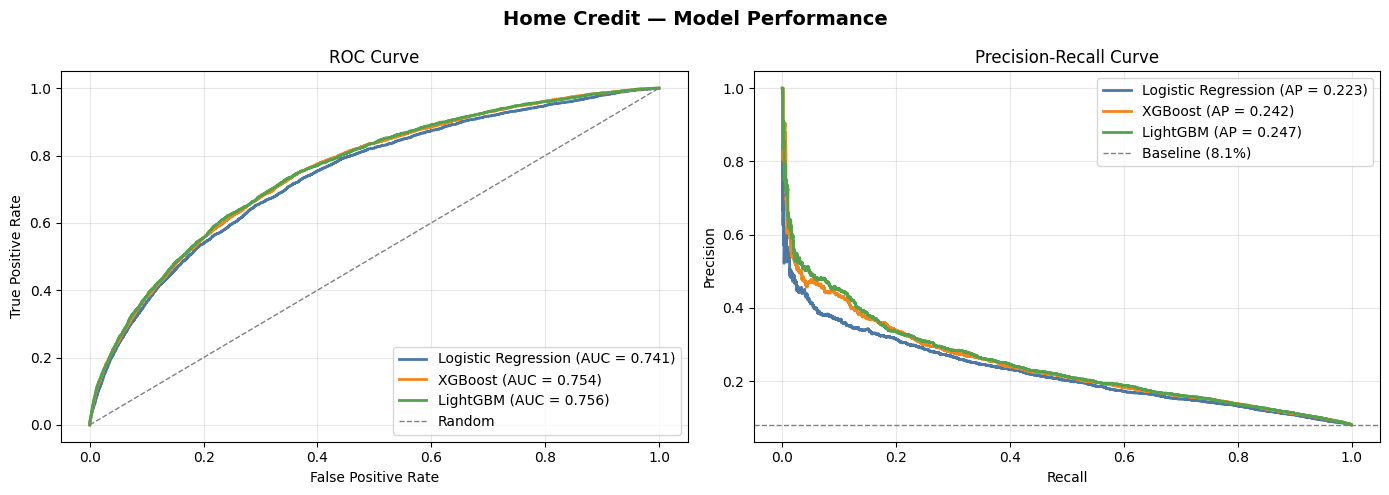

In [63]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

model_probs = {
    'Logistic Regression': lr_probs,
    'XGBoost': xgb_probs,
    'LightGBM': lgbm_probs
}

colors = ['#4C78A8', '#F58518', '#54A24B']

for (name, probs), color in zip(model_probs.items(), colors):

    # ROC curve
    fpr, tpr, _ = roc_curve(y_test, probs)
    auc = roc_auc_score(y_test, probs)

    axes[0].plot(
        fpr, tpr,
        label=f'{name} (AUC = {auc:.3f})',
        color=color,
        linewidth=2
    )

    # Precision-Recall curve
    precision, recall, _ = precision_recall_curve(y_test, probs)
    ap = average_precision_score(y_test, probs)

    axes[1].plot(
        recall, precision,
        label=f'{name} (AP = {ap:.3f})',
        color=color,
        linewidth=2
    )


# ROC baseline
axes[0].plot(
    [0, 1], [0, 1],
    '--',
    color='gray',
    linewidth=1,
    label='Random'
)

axes[0].set_title('ROC Curve')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].legend()
axes[0].grid(alpha=0.3)


# PR baseline
axes[1].axhline(
    y=y_test.mean(),
    linestyle='--',
    color='gray',
    linewidth=1,
    label=f'Baseline ({y_test.mean():.1%})'
)

axes[1].set_title('Precision-Recall Curve')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].legend()
axes[1].grid(alpha=0.3)


fig.suptitle(
    'Home Credit — Model Performance',
    fontsize=14,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

## 4. SHAP Explainability

SHAP values are computed on a **2,000-row stratified sample** of the test set (1,800 non-defaults + 200 defaults). Computing exact SHAP values on the full 46k test set would take several hours — sampling is standard practice for large datasets and preserves class proportions.

- **TreeExplainer** for XGBoost and LightGBM
- **LinearExplainer** for Logistic Regression (requires scaled data)

In [64]:
import shap

print("\nUsing 2,000-row stratified SHAP sample")

np.random.seed(42)
idx_sample = np.concatenate([
    np.random.choice(np.where(y_test == 0)[0], 1840, replace=False),
    np.random.choice(np.where(y_test == 1)[0], 160, replace=False)
])
np.random.shuffle(idx_sample)

# Extract fitted scaler and LR model from pipeline
scaler_hc   = best_lr.named_steps['scaler']
lr_model_hc = best_lr.named_steps['model']

# Transform test data using the fitted scaler
X_train_scaled_hc = scaler_hc.transform(X_train)
X_test_scaled_hc = scaler_hc.transform(X_test)

X_shap        = X_test.iloc[idx_sample].reset_index(drop=True)
X_shap_scaled = X_test_scaled_hc[idx_sample]
y_shap        = y_test.iloc[idx_sample].reset_index(drop=True)
print(f"SHAP sample: {len(X_shap)} rows | Default rate: {y_shap.mean():.1%}")


Using 2,000-row stratified SHAP sample
SHAP sample: 2000 rows | Default rate: 8.0%


In [65]:
explainer_xgb  = shap.TreeExplainer(best_xgb)
shap_xgb       = explainer_xgb.shap_values(X_shap)

explainer_lgbm = shap.TreeExplainer(best_lgbm)
shap_lgbm      = explainer_lgbm.shap_values(X_shap)

explainer_lr   = shap.LinearExplainer(lr_model_hc, X_train_scaled_hc[:1000])
shap_lr        = explainer_lr.shap_values(X_shap_scaled)

if isinstance(shap_lgbm, list):
    shap_lgbm = shap_lgbm[1]
if isinstance(shap_xgb, list):
    shap_xgb = shap_xgb[1]

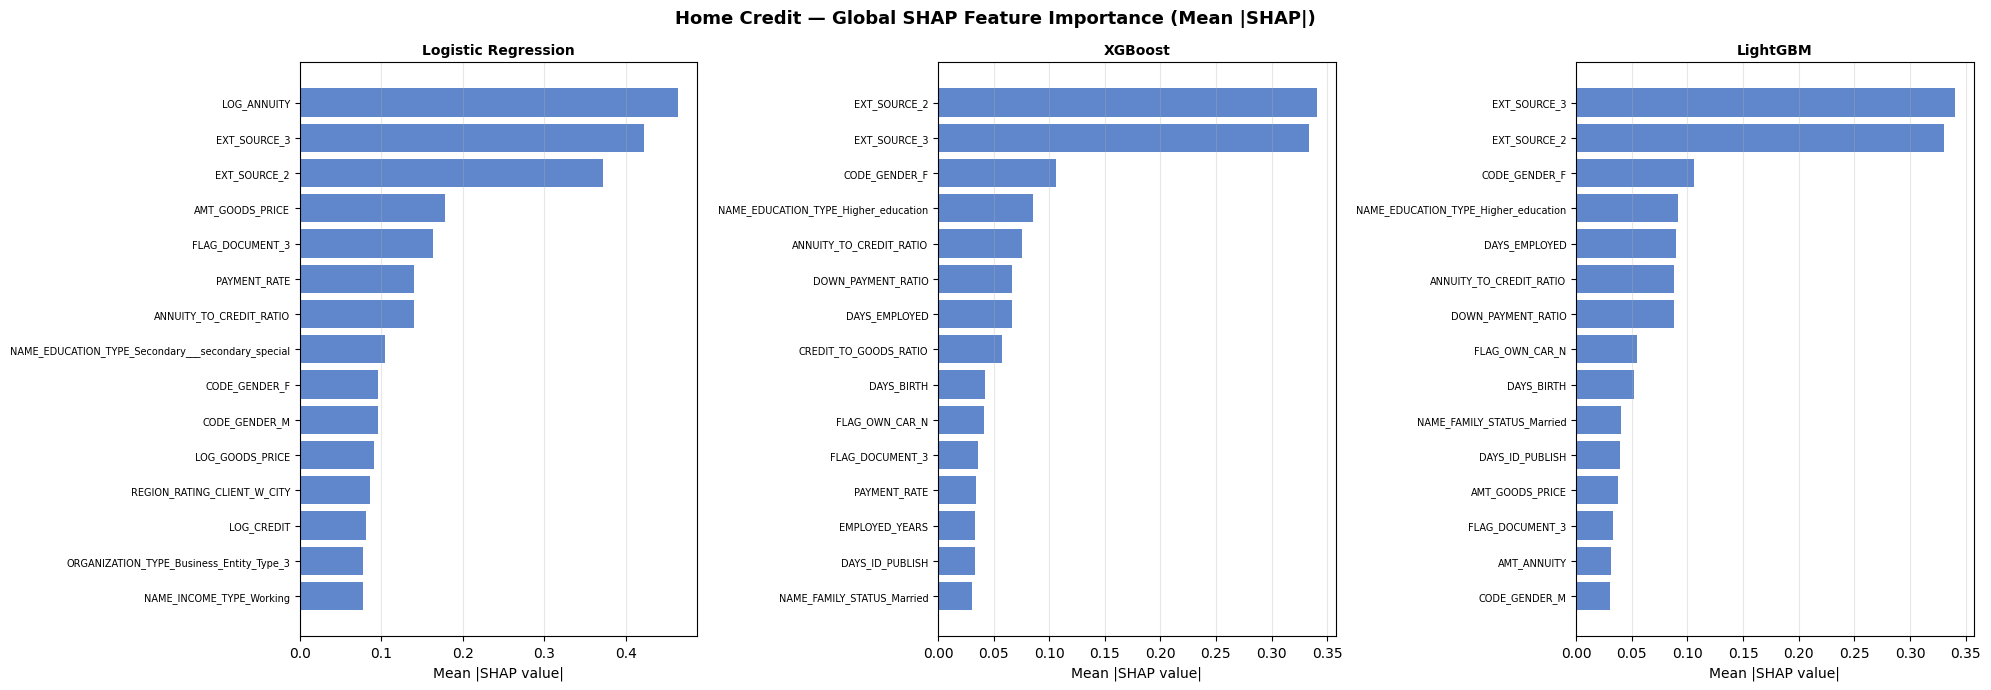

In [66]:
fig, axes = plt.subplots(1, 3, figsize=(20, 7))
fig.suptitle('Home Credit — Global SHAP Feature Importance (Mean |SHAP|)',
             fontweight='bold', fontsize=13)

shap_sets = [
    ('Logistic Regression', shap_lr,   X_shap),
    ('XGBoost',             shap_xgb,  X_shap),
    ('LightGBM',            shap_lgbm, X_shap),
]

for ax, (name, sv, xdata) in zip(axes, shap_sets):
    mean_abs = np.abs(sv).mean(axis=0)
    imp_df   = pd.DataFrame({
        'feature':    xdata.columns,
        'importance': mean_abs
    }).sort_values('importance', ascending=True).tail(15)

    ax.barh(imp_df['feature'], imp_df['importance'],
            color='#4472C4', alpha=0.85)
    ax.set_title(name, fontweight='bold', fontsize=10)
    ax.set_xlabel('Mean |SHAP value|')
    ax.tick_params(axis='y', labelsize=7)
    ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

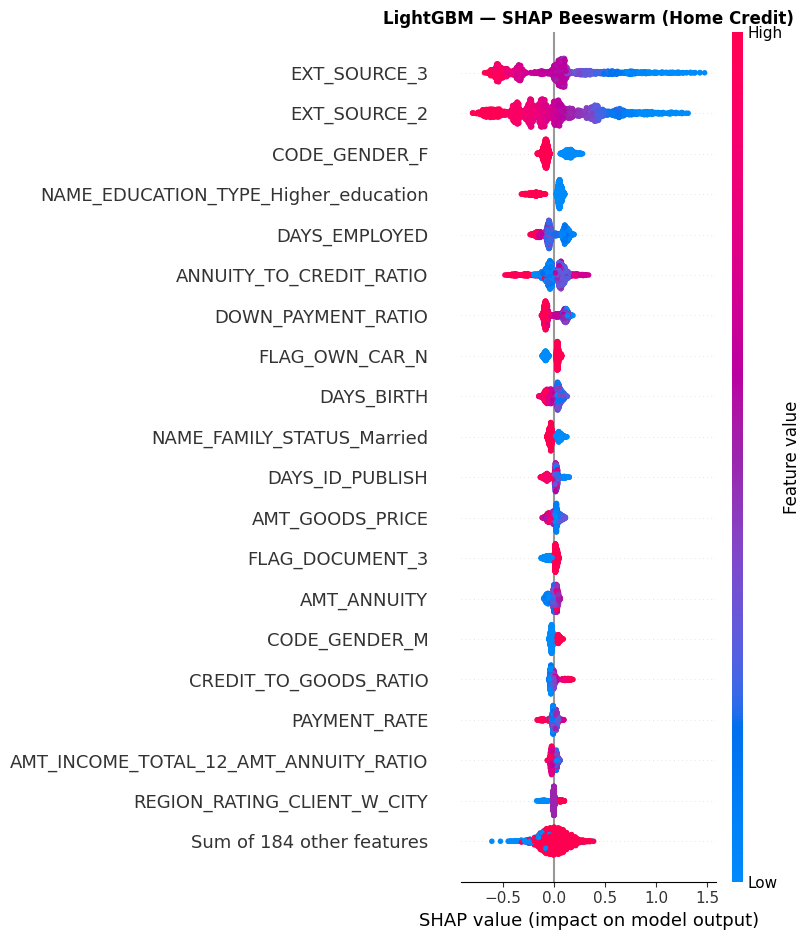

In [67]:
best_shap = {'Logistic Regression': shap_lr,
             'XGBoost':             shap_xgb,
             'LightGBM':            shap_lgbm}[best_model_name]

best_exp_val = {'Logistic Regression': explainer_lr.expected_value,
                'XGBoost':             float(explainer_xgb.expected_value) if hasattr(explainer_xgb.expected_value, '__len__') else explainer_xgb.expected_value,
                'LightGBM':            float(explainer_lgbm.expected_value) if hasattr(explainer_lgbm.expected_value, '__len__') else explainer_lgbm.expected_value}[best_model_name]

best_xdata = X_shap_scaled if best_model_name == 'Logistic Regression' else X_shap

explanation = shap.Explanation(
    values=best_shap,
    base_values=best_exp_val,
    data=best_xdata.values,
    feature_names=best_xdata.columns.tolist()
)

plt.figure(figsize=(11, 9))
shap.plots.beeswarm(explanation, max_display=20, show=False)
plt.title(f'{best_model_name} — SHAP Beeswarm (Home Credit)', fontweight='bold')
plt.tight_layout()
plt.show()

In [68]:
def top_features(sv, cols, n=10):
    return [cols[i] for i in np.argsort(np.abs(sv).mean(axis=0))[::-1][:n]]

lgbm_top = top_features(shap_lgbm, X_shap.columns.tolist())
xgb_top  = top_features(shap_xgb,  X_shap.columns.tolist())
lr_top   = top_features(shap_lr,   X_shap.columns.tolist())

print(f"\nTop 10 SHAP features:")
print(f"{'Rank':<5} {'LightGBM':<35} {'XGBoost':<35} {'LR':<35}")
print("-" * 110)
for i in range(10):
    print(f"{i+1:<5} {lgbm_top[i]:<35} {xgb_top[i]:<35} {lr_top[i]:<35}")


Top 10 SHAP features:
Rank  LightGBM                            XGBoost                             LR                                 
--------------------------------------------------------------------------------------------------------------
1     EXT_SOURCE_3                        EXT_SOURCE_2                        LOG_ANNUITY                        
2     EXT_SOURCE_2                        EXT_SOURCE_3                        EXT_SOURCE_3                       
3     CODE_GENDER_F                       CODE_GENDER_F                       EXT_SOURCE_2                       
4     NAME_EDUCATION_TYPE_Higher_education NAME_EDUCATION_TYPE_Higher_education AMT_GOODS_PRICE                    
5     DAYS_EMPLOYED                       ANNUITY_TO_CREDIT_RATIO             FLAG_DOCUMENT_3                    
6     ANNUITY_TO_CREDIT_RATIO             DOWN_PAYMENT_RATIO                  PAYMENT_RATE                       
7     DOWN_PAYMENT_RATIO                  DAYS_EMPLOYED           

**SHAP feature ranking comparison:** LightGBM and XGBoost show similar top features (both dominated by EXT_SOURCE_2 and EXT_SOURCE_3), confirming that external credit bureau scores are the primary risk signal in this dataset. Logistic Regression's ranking diverges in the mid-tier features, reflecting its inability to capture non-linear interactions that tree-based models exploit.

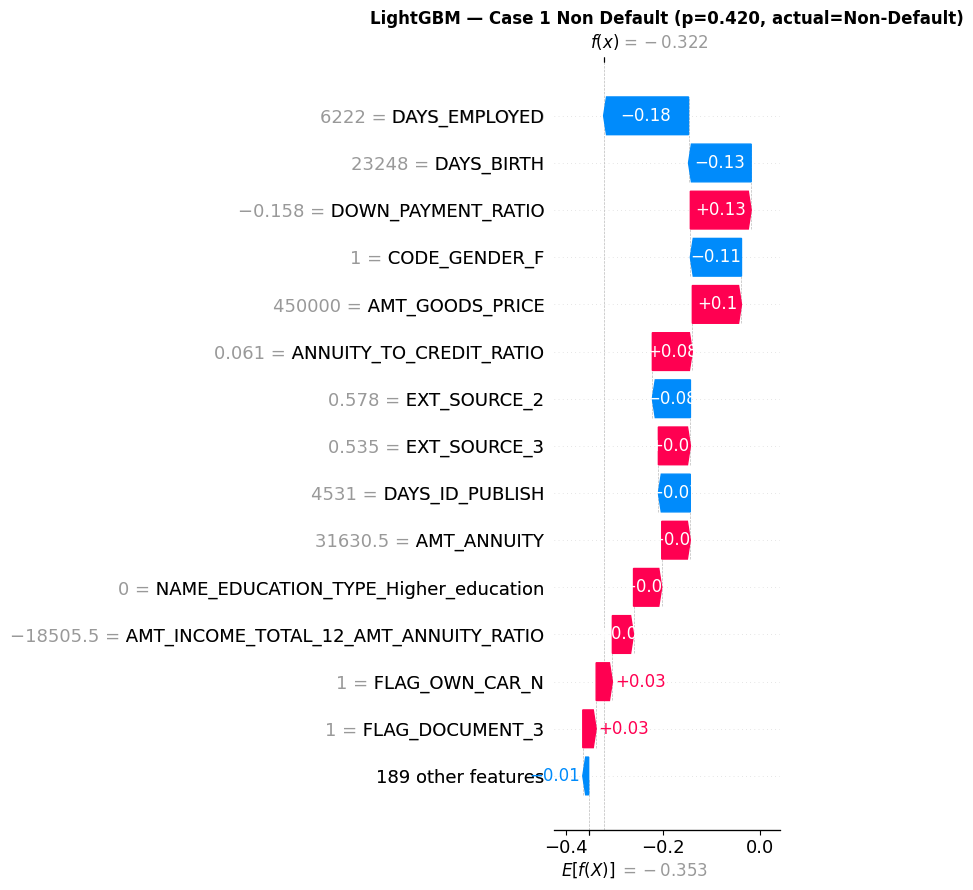

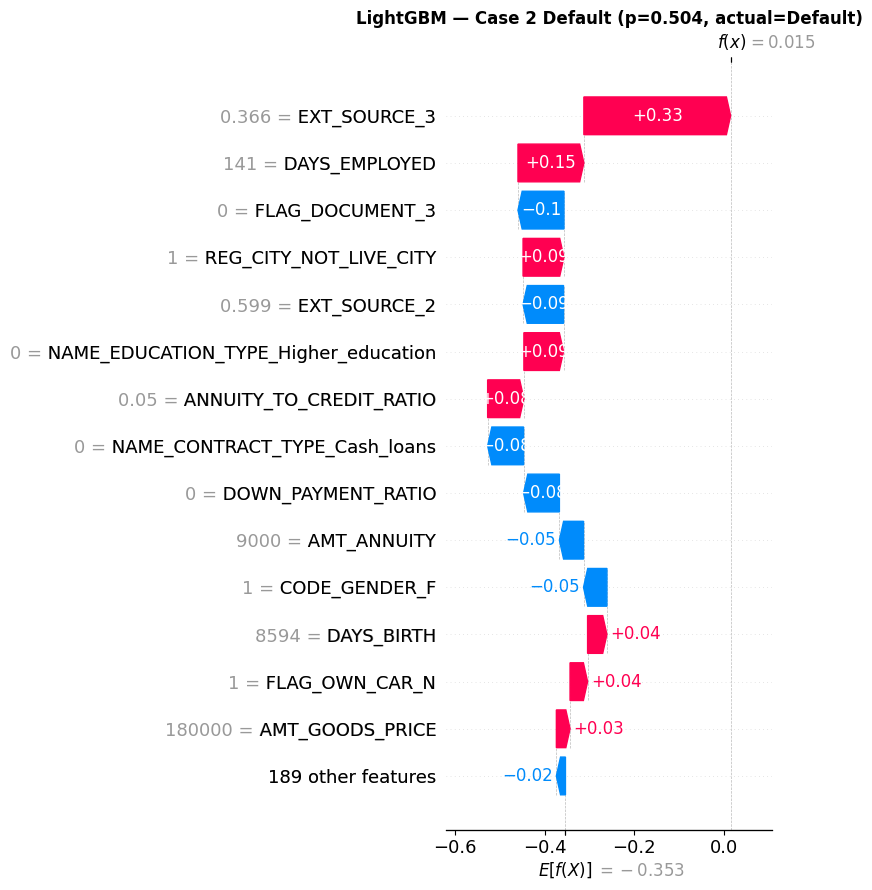

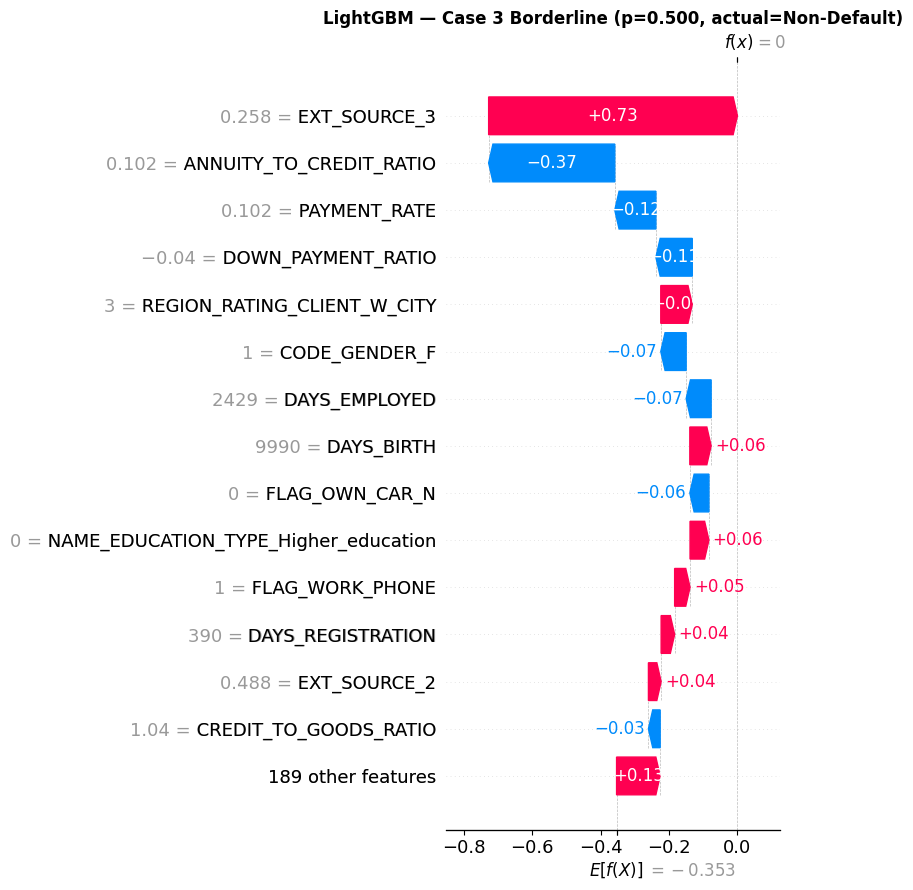

In [69]:
# Use the SHAP sample for case studies
shap_probs  = best_model.predict_proba(best_xdata)[:, 1]
shap_preds  = (shap_probs >= 0.5).astype(int)
y_shap_arr  = y_shap.values

cases = {
    'case_1_non_default': np.where((shap_preds==0) & (y_shap_arr==0))[0],
    'case_2_default':     np.where((shap_preds==1) & (y_shap_arr==1))[0],
    'case_3_borderline':  [np.argmin(np.abs(shap_probs - 0.5))],
}

for case_name, idxs in cases.items():
    if len(idxs) == 0:
        print(f"  {case_name}: no examples found")
        continue
    idx  = idxs[0]
    prob = shap_probs[idx]
    act  = y_shap_arr[idx]

    exp_single = shap.Explanation(
        values=best_shap[idx],
        base_values=best_exp_val,
        data=best_xdata.iloc[idx].values,
        feature_names=best_xdata.columns.tolist()
    )
    plt.figure(figsize=(11, 7))
    shap.plots.waterfall(exp_single, max_display=15, show=False)
    plt.title(f'{best_model_name} — {case_name.replace("_", " ").title()} '
              f'(p={prob:.3f}, actual={"Default" if act==1 else "Non-Default"})',
              fontweight='bold')
    plt.tight_layout()
    plt.show()

## 5. DiCE Counterfactual Explanations

DiCE requires original (pre-encoded) feature data and a **scikit-learn Pipeline** that handles encoding internally. A separate LightGBM pipeline (`pipe_lgbm`) is built on the unencoded dataframe (`df`) for this purpose.

**Immutable features** (cannot be changed by the applicant): age, sex, historical dates, geographic ratings, external credit scores, social circle behaviour, credit bureau enquiry history, and engineered ratio features.

**Method:** `random` — used for computational efficiency on the large Home Credit test set.

In [70]:
import dice_ml
from dice_ml import Dice
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder


In [71]:
X_orig = df.drop('TARGET', axis=1)
y_orig = df['TARGET']

In [72]:
# Same split to get aligned training data
X_tr_o, X_tmp_o, y_tr_o, _ = train_test_split(X_orig, y_orig,
                                                 test_size=0.30,
                                                 random_state=42,
                                                 stratify=y_orig)
X_val_o, X_te_o, _, y_te_o = train_test_split(X_tmp_o, _,
                                                test_size=0.50,
                                                random_state=42,
                                                stratify=_)

In [73]:
scale_pos_weight_o = (y_tr_o == 0).sum() / (y_tr_o == 1).sum()

In [74]:
preprocessor = ColumnTransformer(transformers=[
    ('num', 'passthrough', numerical_features),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features),
])

pipe_lgbm = Pipeline([
    ('prep', preprocessor),
    ('clf',  LGBMClassifier(
        **study_lgbm.best_params,
        scale_pos_weight = scale_pos_weight_o,
        random_state=42,
        n_jobs=-1,
        verbose=-1,
    ))
])
pipe_lgbm.fit(X_tr_o, y_tr_o)

,steps,"[('prep', ...), ('clf', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [75]:
from sklearn.metrics import roc_auc_score as ras
pipe_auc = ras(y_te_o, pipe_lgbm.predict_proba(X_te_o)[:, 1])
print(f"  Pipeline AUC on test (original features): {pipe_auc:.4f}")

  Pipeline AUC on test (original features): 0.7564


In [76]:
# talk about only usibg a sample and it not working
# np.random.seed(42)
# sample_idx = np.concatenate([
#     np.random.choice(np.where(y_tr_o == 0)[0], 430, replace=False),
#     np.random.choice(np.where(y_tr_o == 1)[0], 70,  replace=False)
# ])
train_dice = X_tr_o.copy()
train_dice['TARGET'] = y_tr_o

print(f"DiCE training sample: {len(train_dice)} rows | Default rate: {train_dice['TARGET'].mean():.1%}")

dice_data = dice_ml.Data(
    dataframe=train_dice,
    continuous_features=numerical_features,
    categorical_features=categorical_features,
    outcome_name='TARGET'
)
dice_model_obj = dice_ml.Model(
    model=pipe_lgbm,
    backend='sklearn',
    model_type='classifier'
)
dice_explainer = Dice(dice_data, dice_model_obj, method='random')

DiCE training sample: 215254 rows | Default rate: 8.1%


In [77]:
# Predict test set
threshold  = thresh_lgbm
test_probs = pipe_lgbm.predict_proba(X_te_o)[:, 1]
rejected   = np.where(test_probs >= threshold)[0] #fair throshold helped improving the results from 60% to 80%

print(f"\nRejected applicants in test set: {len(rejected):,}")
print("Generating counterfactuals for first 5:")

immutable = [
    # Demographics / age
    'AGE_YEARS', 'CODE_GENDER', 'DAYS_BIRTH',
    # Historical information
    'DAYS_ID_PUBLISH', 'DAYS_REGISTRATION', 'DAYS_LAST_PHONE_CHANGE',
    # Geographic characteristics
    'REGION_POPULATION_RELATIVE', 'REGION_RATING_CLIENT',
    'REGION_RATING_CLIENT_W_CITY', 'REG_REGION_NOT_LIVE_REGION',
    'REG_REGION_NOT_WORK_REGION', 'LIVE_REGION_NOT_WORK_REGION',
    'REG_CITY_NOT_LIVE_CITY', 'REG_CITY_NOT_WORK_CITY', 'LIVE_CITY_NOT_WORK_CITY',
    # External credit information (not directly controllable)
    'EXT_SOURCE_2', 'EXT_SOURCE_3',
    # Social-circle information
    'OBS_30_CNT_SOCIAL_CIRCLE', 'DEF_30_CNT_SOCIAL_CIRCLE',
    'OBS_60_CNT_SOCIAL_CIRCLE', 'DEF_60_CNT_SOCIAL_CIRCLE',
    # Credit bureau enquiry history
    'AMT_REQ_CREDIT_BUREAU_HOUR', 'AMT_REQ_CREDIT_BUREAU_DAY',
    'AMT_REQ_CREDIT_BUREAU_WEEK', 'AMT_REQ_CREDIT_BUREAU_MON',
    'AMT_REQ_CREDIT_BUREAU_QRT', 'AMT_REQ_CREDIT_BUREAU_YEAR',
]
immutable  = [c for c in immutable if c in X_te_o.columns]
vary_cols  = [c for c in X_te_o.columns if c not in immutable]

print(f"Immutable features: {len(immutable)}")
print(f"Features allowed to vary: {len(vary_cols)}")

results_dice = []
valid_count  = 0
n_to_test    = min(5, len(rejected))

for i, idx in enumerate(rejected[:n_to_test]):
    query     = X_te_o.iloc[[idx]].copy()
    orig_prob = pipe_lgbm.predict_proba(query)[0, 1]

    try:
        cf = dice_explainer.generate_counterfactuals(
            query,
            total_CFs=3,
            desired_class=0,
            features_to_vary=vary_cols, 
            permitted_range={
                'AMT_CREDIT':    [10000, 4000000],
                'AMT_ANNUITY':   [1000,  200000],
                'EMPLOYED_YEARS':[0,     40],
                'CNT_CHILDREN':  [0,     10],
            }
        )

        cf_df = cf.cf_examples_list[0].final_cfs_df

        if cf_df is not None and not cf_df.empty:
            valid_count += 1

            if i < 3:
                print(f"\nApplicant {idx} (p_default={orig_prob:.3f})")
                print("Changes needed for approval:")
                original      = query.iloc[0]
                counterfactual = cf_df.iloc[0]
                changes = [
                    (col, original[col], counterfactual[col])
                    for col in vary_cols
                    if col in cf_df.columns and original[col] != counterfactual[col]
                ]
                if changes:
                    for col, old, new in changes:
                        print(f"  {col}: {old} → {new}")
                else:
                    print("  No feature changes found.")

            results_dice.append({
                'applicant_idx': idx,
                'original_prob': round(orig_prob, 3),
                'n_valid_cfs':   len(cf_df)
            })

    except Exception as e:
        print(f"Applicant {idx}: failed — {str(e)[:150]}")

validity_rate = valid_count / n_to_test if n_to_test > 0 else 0
print(f"\nDiCE validity rate: {valid_count}/{n_to_test} = {validity_rate:.0%}")
print(f"Proposal target: ≥90% — {'MET' if validity_rate >= 0.90 else 'NOT MET'}")


Rejected applicants in test set: 45,444
Generating counterfactuals for first 5:
Immutable features: 27
Features allowed to vary: 63


100%|██████████| 1/1 [00:06<00:00,  6.45s/it]



Applicant 0 (p_default=0.701)
Changes needed for approval:
  NAME_CONTRACT_TYPE: Cash loans → Revolving loans
  NAME_EDUCATION_TYPE: Secondary / secondary special → Higher education
  NAME_HOUSING_TYPE: House / apartment → Rented apartment
  DAYS_EMPLOYED: 766.0 → 8496.7
  FLAG_DOCUMENT_8: 0 → 1
  INCOME_TO_BIRTH_RATIO: 8.099935200518395 → 17.034761


100%|██████████| 1/1 [00:06<00:00,  6.18s/it]



Applicant 1 (p_default=0.254)
Changes needed for approval:
  LOG_INCOME: 12.36308066783498 → 14.292381


100%|██████████| 1/1 [00:07<00:00,  7.72s/it]



Applicant 2 (p_default=0.281)
Changes needed for approval:
  ANNUITY_TO_INCOME_RATIO: 0.2084381472164692 → 0.70229144


100%|██████████| 1/1 [00:05<00:00,  5.36s/it]

No Counterfactuals found for the given configuration, perhaps try with different parameters... ; total time taken: 00 min 05 sec
Applicant 4: failed — No counterfactuals found for any of the query points! Kindly check your configuration.

DiCE validity rate: 4/5 = 80%
Proposal target: ≥90% — NOT MET


## 6. Fairness Audit

Fairness is evaluated using **Microsoft Fairlearn** across two sensitive attributes:
- **Age group** (6 bins: <25 / 25–35 / 35–45 / 45–55 / 55–65 / 65+)
- **Sex** (Male / Female)

Thresholds: DPD < 0.10, EOD < 0.10, DIR > 0.80 (the '80% rule' from US fair lending practice, referenced in Kozodoi et al., 2022).

Fairlearn imports were moved to the top of the Home Credit section to ensure availability in `optimal_fair_threshold`.

In [78]:
from fairlearn.metrics import (
    demographic_parity_difference,
    equalized_odds_difference,
    demographic_parity_ratio,
    MetricFrame,
)
from sklearn.metrics import accuracy_score, precision_score, recall_score

In [79]:
model_preds_dict = {
    'Logistic Regression': lr_preds,
    'XGBoost':             xgb_preds,
    'LightGBM':            lgbm_preds,
}

In [80]:
def compute_fairness(y_true, y_pred, sensitive, model_name, feature_name):
    dpd       = demographic_parity_difference(y_true=y_true, y_pred=y_pred,
                                                sensitive_features=sensitive)
    eod       = equalized_odds_difference(y_true=y_true, y_pred=y_pred,
                                            sensitive_features=sensitive)
    dir_score = demographic_parity_ratio(y_true=y_true, y_pred=y_pred,
                                            sensitive_features=sensitive)
    return {
        'Model':                  model_name,
        'Sensitive Feature':      feature_name,
        'Demographic Parity Diff': round(abs(dpd),      2),
        'Equalised Odds Diff':     round(abs(eod),      2),
        'Disparate Impact Ratio':  round(dir_score,     2),
        'DPD Pass (<0.10)':        'PASS' if abs(dpd)      <= 0.10 else 'FAIL',
        'EOD Pass (<0.10)':        'PASS' if abs(eod)      <= 0.10 else 'FAIL',
        'DIR Pass (>0.80)':        'PASS' if dir_score     >= 0.80 else 'FAIL',
    }

`sensitive_age_val` and `sensitive_sex_val` were defined earlier during threshold optimisation and are reused here.

`sensitive_sex_val` reused from earlier — no redefinition needed.

Fairness metrics are computed for all three models against both sensitive features (age group and sex).

In [81]:
fairness_results = []

for model_name, y_pred in model_preds_dict.items():
    print(f"\n{model_name}:")
    for sensitive, feat_name in [
        (sensitive_age_binned.values, 'Age Group'),
        (sensitive_sex_test.values,   'Sex'),
    ]:
        row = compute_fairness(y_test.values, y_pred, sensitive,
                               model_name, feat_name)
        fairness_results.append(row)
        print(f"  [{feat_name}] DPD={row['Demographic Parity Diff']:.2f} {row['DPD Pass (<0.10)']} | "
              f"EOD={row['Equalised Odds Diff']:.2f} {row['EOD Pass (<0.10)']} | "
              f"DIR={row['Disparate Impact Ratio']:.2f} {row['DIR Pass (>0.80)']}")

fairness_df = pd.DataFrame(fairness_results)


Logistic Regression:
  [Age Group] DPD=0.11 FAIL | EOD=0.11 FAIL | DIR=0.89 PASS
  [Sex] DPD=0.03 PASS | EOD=0.03 PASS | DIR=0.97 PASS

XGBoost:
  [Age Group] DPD=0.08 PASS | EOD=0.08 PASS | DIR=0.92 PASS
  [Sex] DPD=0.01 PASS | EOD=0.01 PASS | DIR=0.99 PASS

LightGBM:
  [Age Group] DPD=0.09 PASS | EOD=0.09 PASS | DIR=0.91 PASS
  [Sex] DPD=0.01 PASS | EOD=0.01 PASS | DIR=0.99 PASS


In [82]:
print("\nGroup-level breakdown — LightGBM vs Age Group:")
mf_age = MetricFrame(
    metrics={
        'accuracy':       accuracy_score,
        'precision':      lambda yt, yp: precision_score(yt, yp, zero_division=0),
        'recall':         recall_score,
        'selection_rate': lambda yt, yp: float(np.mean(yp)),
    },
    y_true=y_test.values,
    y_pred=lgbm_preds,
    sensitive_features=sensitive_age_binned.values,
)
print(mf_age.by_group.to_string())


Group-level breakdown — LightGBM vs Age Group:
                     accuracy  precision    recall  selection_rate
sensitive_feature_0                                               
25-35                0.107268   0.101875  1.000000        0.993996
35-45                0.096308   0.084312  1.000000        0.986900
45-55                0.088027   0.074387  0.997392        0.985057
55-65                0.078932   0.056438  0.993878        0.975800
65+                  0.111230   0.028070  1.000000        0.914439
<25                  0.123434   0.123027  1.000000        0.999536


In [83]:
print("\nGroup-level breakdown — LightGBM vs Sex:")
mf_sex = MetricFrame(
    metrics={
        'accuracy':       accuracy_score,
        'precision':      lambda yt, yp: precision_score(yt, yp, zero_division=0),
        'recall':         recall_score,
        'selection_rate': lambda yt, yp: float(np.mean(yp)),
    },
    y_true=y_test.values,
    y_pred=lgbm_preds,
    sensitive_features=sensitive_sex_test.values,
)
print(mf_sex.by_group.to_string())


Group-level breakdown — LightGBM vs Sex:
                     accuracy  precision    recall  selection_rate
sensitive_feature_0                                               
Female               0.089894   0.071914  0.997675        0.980451
Male                 0.105857   0.100814  1.000000        0.994392


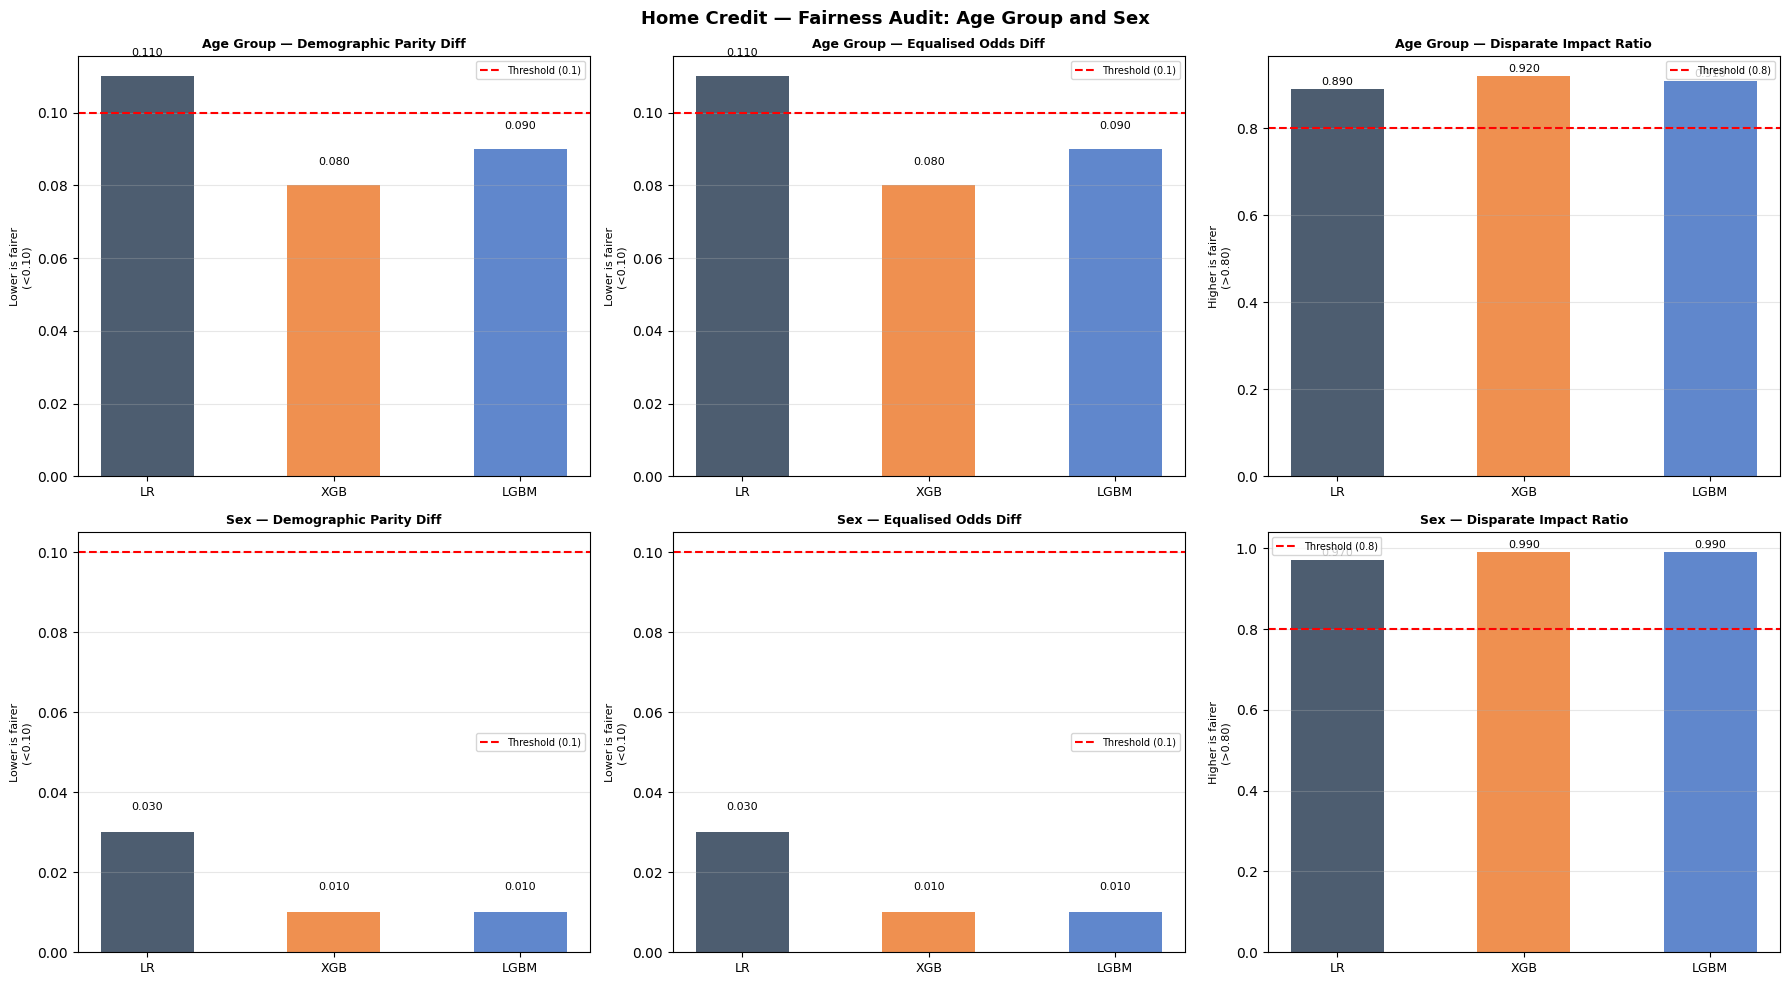

In [84]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('Home Credit — Fairness Audit: Age Group and Sex',
             fontweight='bold', fontsize=13)

metrics_plot = [
    ('Demographic Parity Diff', 0.10, 'Lower is fairer\n(<0.10)'),
    ('Equalised Odds Diff',     0.10, 'Lower is fairer\n(<0.10)'),
    ('Disparate Impact Ratio',  0.80, 'Higher is fairer\n(>0.80)'),
]
model_list  = ['Logistic Regression', 'XGBoost', 'LightGBM']
x           = np.arange(len(model_list))
bar_colors  = ['#2E4057', '#ED7D31', '#4472C4']
sensitive_groups = ['Age Group', 'Sex']

for row_i, sf in enumerate(sensitive_groups):
    sf_df = fairness_df[fairness_df['Sensitive Feature'] == sf]
    for col_i, (metric, threshold, ylabel) in enumerate(metrics_plot):
        ax   = axes[row_i][col_i]
        vals = sf_df[metric].values
        bars = ax.bar(x, vals, color=bar_colors, alpha=0.85, width=0.5)
        ax.axhline(y=threshold, color='red', linestyle='--', lw=1.5,
                   label=f'Threshold ({threshold})')
        ax.set_xticks(x)
        ax.set_xticklabels(['LR', 'XGB', 'LGBM'], fontsize=9)
        ax.set_title(f'{sf} — {metric}', fontweight='bold', fontsize=9)
        ax.set_ylabel(ylabel, fontsize=8)
        ax.legend(fontsize=7)
        ax.grid(axis='y', alpha=0.3)
        for bar, val in zip(bars, vals):
            ax.text(bar.get_x() + bar.get_width()/2,
                    bar.get_height() + 0.005,
                    f'{val:.3f}', ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.show()

## 7. Final Summary

In [85]:
print("\nPerformance Summary:")
print(results_df.to_string())

print("\nFairness Summary:")
print(fairness_df[['Model', 'Sensitive Feature',
                   'Demographic Parity Diff', 'Equalised Odds Diff',
                   'Disparate Impact Ratio',
                   'DPD Pass (<0.10)', 'EOD Pass (<0.10)',
                   'DIR Pass (>0.80)']].to_string(index=False))


Performance Summary:
                     AUC-ROC  AUC-PR    Gini      KS      F1   Brier  Train Time
Model                                                                           
Logistic Regression   0.7407  0.2235  0.4814  0.3604  0.1565  0.1988      2050.0
XGBoost               0.7543  0.2425  0.5086  0.3825  0.1510  0.2012      1459.0
LightGBM              0.7564  0.2473  0.5128  0.3852  0.1513  0.2002      1170.0

Fairness Summary:
              Model Sensitive Feature  Demographic Parity Diff  Equalised Odds Diff  Disparate Impact Ratio DPD Pass (<0.10) EOD Pass (<0.10) DIR Pass (>0.80)
Logistic Regression         Age Group                     0.11                 0.11                    0.89             FAIL             FAIL             PASS
Logistic Regression               Sex                     0.03                 0.03                    0.97             PASS             PASS             PASS
            XGBoost         Age Group                     0.08               